# Comparing Daily Temperature Forecasting Across Eight Indian Cities

**NOAA Global Summary of the Day (GSOD), 2010–2024**  
**Target:** daily mean temperature in °C  
**Locations:** Bengaluru, Delhi, Mumbai, Chennai, Kolkata, Hyderabad, Ahmedabad, and Pune

This notebook brings the city comparison and the remaining forecasting rubric into one reproducible analysis. It uses the saved, out-of-sample analysis artifacts in this repository so that opening and running the notebook does not launch the long model-selection sweep again. The scripts in `src/` are the source of the model fits; their per-city candidate scores and selected orders are loaded below.

## 1. Research question and rubric scope

> How do the temporal patterns and one-step forecast errors of daily mean temperature compare across eight major Indian cities, and which forecasting model families work best under the same evaluation setup?

This is a station-level, observational comparison. The metrics describe these NOAA stations and this test period; they do not establish causal effects or represent every neighbourhood in each city.

The notebook covers the original case-study rubric (research question, data understanding, visualization, trend/seasonality, stationarity, ACF/PACF, and initial findings) and the remaining model-comparison rubric (ARIMA-family selection, Holt-Winters, ML/DL, baselines, accuracy, comparisons, residuals, conclusion, and contribution record).

**Two analysis pipelines feed this notebook.** They share the same data, test dates and seeds, but answer different questions:

| | Stage A — base city pipeline | Stage B — model-family extension |
|---|---|---|
| Script | `src/run_all_cities.py` | `src/rubric_extension.py` |
| Saved results | `results/city_comparison.json`, `results/cities/` | `results/rubric_extension/` |
| Models | 4 naive baselines, **fixed-order** ARIMA(2,0,2), LSTM, Transformer | the same baselines, LSTM and Transformer **plus** BIC-selected ARIMA/SARIMA/ARMAX/SARIMAX, two Holt-Winters variants, Random Forest, Gradient Boosting |
| Horizons | one-step **and** direct 1/7/14/21/30-day | one-step only |
| Purpose here | descriptive statistics, stationarity, and the **multi-horizon** experiment | the **authoritative one-step model comparison**, order selection, paired tests and residual diagnostics |

Section 7.2 verifies that the models common to both pipelines produce identical test-period scores, so the two sets of results can be read together without contradiction.

In [40]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
while not (ROOT / "src" / "cities.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "cities.py").exists():
    raise FileNotFoundError("Open this notebook from the repository or a subfolder of it.")
sys.path.insert(0, str(ROOT / "src"))
from cities import CITIES

with open(ROOT / "results" / "city_comparison.json", encoding="utf-8") as f:
    base = json.load(f)
with open(ROOT / "results" / "rubric_extension" / "city_model_comparison.json", encoding="utf-8") as f:
    extension = json.load(f)

CITY_NAMES = base["cities"]
base_city = base["per_city_results"]
ext_city = extension["per_city_results"]
print(f"Loaded {len(CITY_NAMES)} cities; test dates: {base_city[CITY_NAMES[0]]['forecast_setup']['test_start']} to {base_city[CITY_NAMES[0]]['forecast_setup']['test_end']}")

Loaded 8 cities; test dates: 2022-10-02 to 2024-12-31


## 2. Dataset and station coverage

Daily temperature comes from NOAA/NCEI GSOD. Each city is represented by one airport or observatory station. GSOD temperature values are converted from °F to °C; the cleaned series is placed on a continuous daily calendar, with short temperature gaps interpolated for the time-series models. Precipitation is kept as a secondary descriptive variable and is not a forecast predictor here.

The same dates and temporal split are used for all cities. The final 15% is held out for forecasting; model order selection and fitting use only the earlier 85%.

In [41]:
station_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    station_rows.append({
        "City": city,
        "NOAA station": CITIES[city]["station"],
        "Station name": b.get("station", {}).get("name", ""),
        "Observations": b["dataset"]["n_obs"],
        "Start": b["dataset"]["start"],
        "End": b["dataset"]["end"],
        "Missing raw temperature": b["dataset"]["missing_temperature_c"],
        "Missing precipitation": b["dataset"]["missing_precipitation_mm"],
    })
stations = pd.DataFrame(station_rows)
display(stations)

# One city's descriptive summary as a concrete example; the table above audits all stations.
display(pd.DataFrame.from_dict(base_city["Bengaluru"]["dataset"]["temp_describe"], orient="index", columns=["Bengaluru daily mean temperature (°C)"]))

,City,NOAA station,Station name,Observations,Start,End,Missing raw temperature,Missing precipitation
0,Bengaluru,43295099999,"BANGALORE, IN",5479,2010-01-01,2024-12-31,27,2594
1,Delhi,42182099999,"SAFDARJUNG, IN",5479,2010-01-01,2024-12-31,37,3748
2,Mumbai,43003099999,"CHHATRAPATI SHIVAJI INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,13,3502
3,Chennai,43279099999,"CHENNAI INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,12,3149
4,Kolkata,42809099999,"NETAJI SUBHASH CHANDRA BOSE INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,20,3966
5,Hyderabad,43128099999,"BEGUMPET AIRPORT, IN",5479,2010-01-01,2024-12-31,15,3341
6,Ahmedabad,42647099999,"AHMEDABAD, IN",5479,2010-01-01,2024-12-31,66,4193
7,Pune,43063099999,"PUNE, IN",5479,2010-01-01,2024-12-31,25,3354


,Bengaluru daily mean temperature (°C)
count,5452.000000
mean,24.106750
std,2.228548
min,18.388889
25%,22.500000
50%,23.777778
75%,25.388889
max,31.611111


## 3. Visual comparison of the eight daily series

Aligned panels make differences in seasonal range and short-term variability easier to compare. The station records use the same 2010–2024 window.

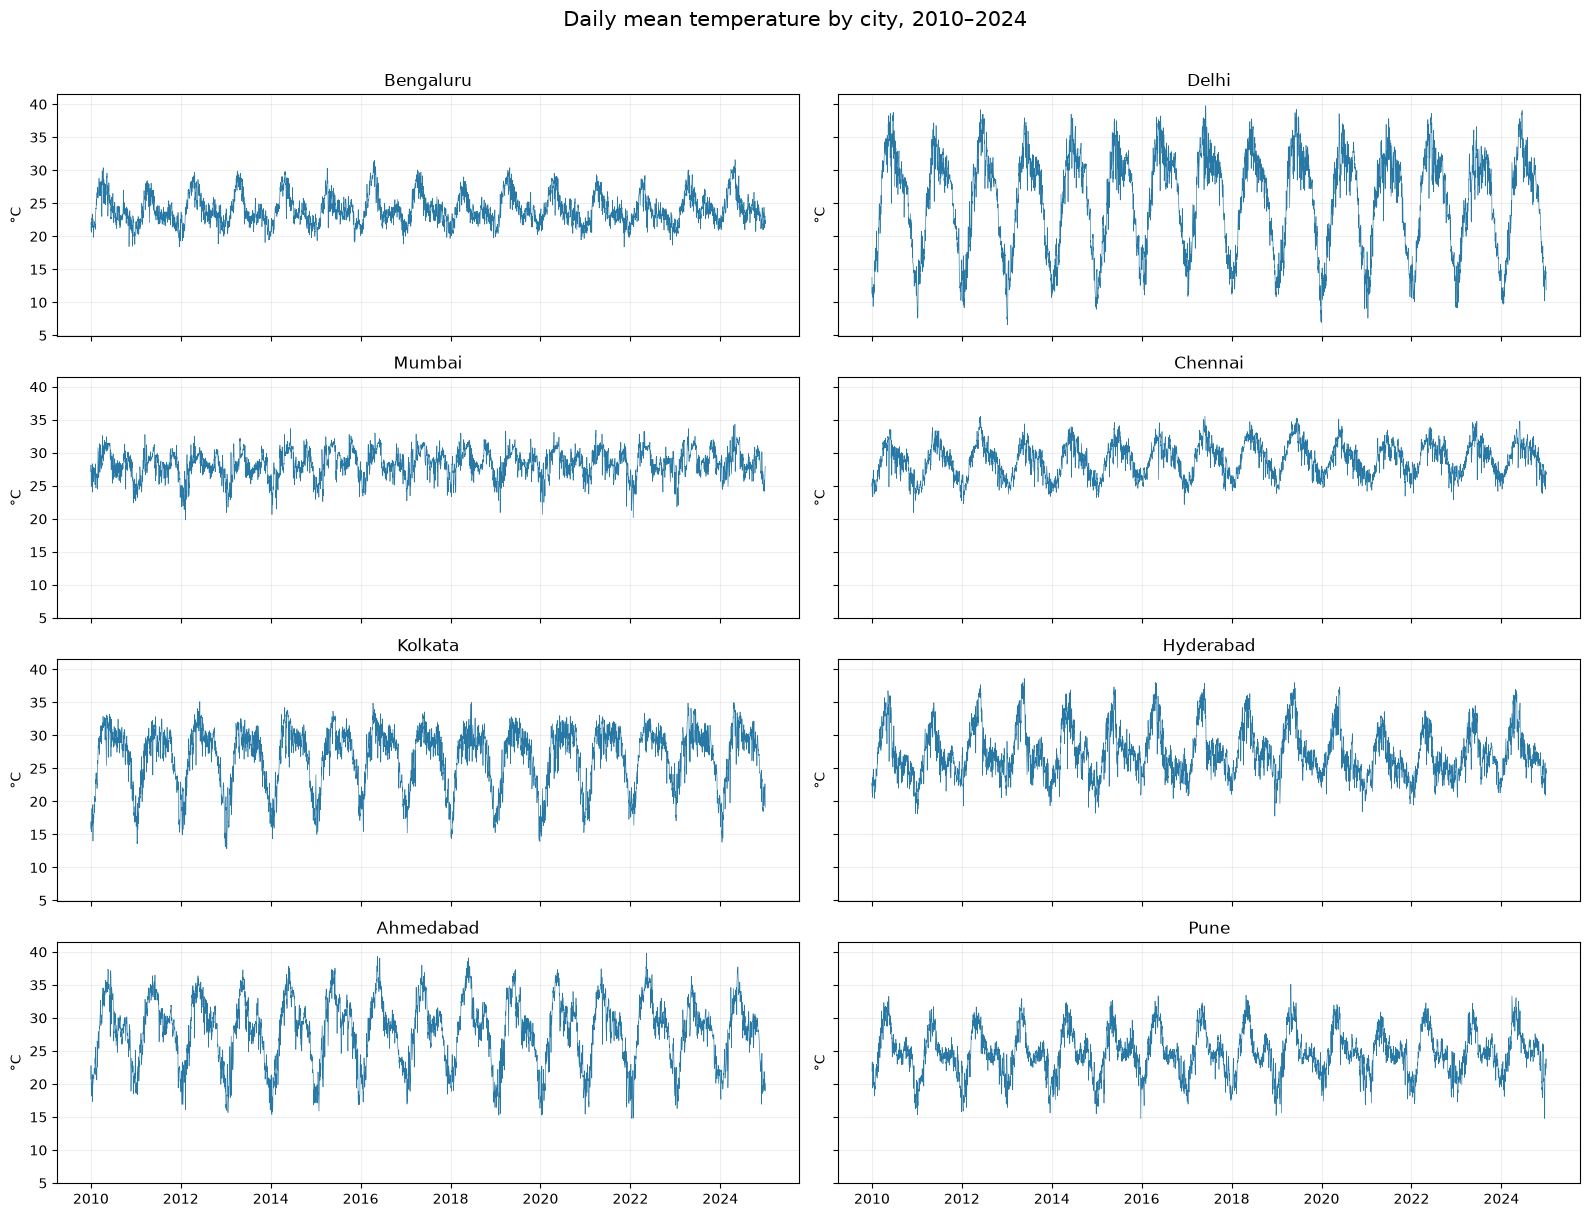

In [42]:
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True, sharey=True)
for ax, city in zip(axes.flat, CITY_NAMES):
    station = CITIES[city]["station"]
    frame = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{station}.csv", parse_dates=["date"])
    ax.plot(frame["date"], frame["temperature_c_interp"], lw=0.45, color="#2878a5")
    ax.set_title(city)
    ax.set_ylabel("°C")
    ax.grid(alpha=0.2)
fig.suptitle("Daily mean temperature by city, 2010–2024", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

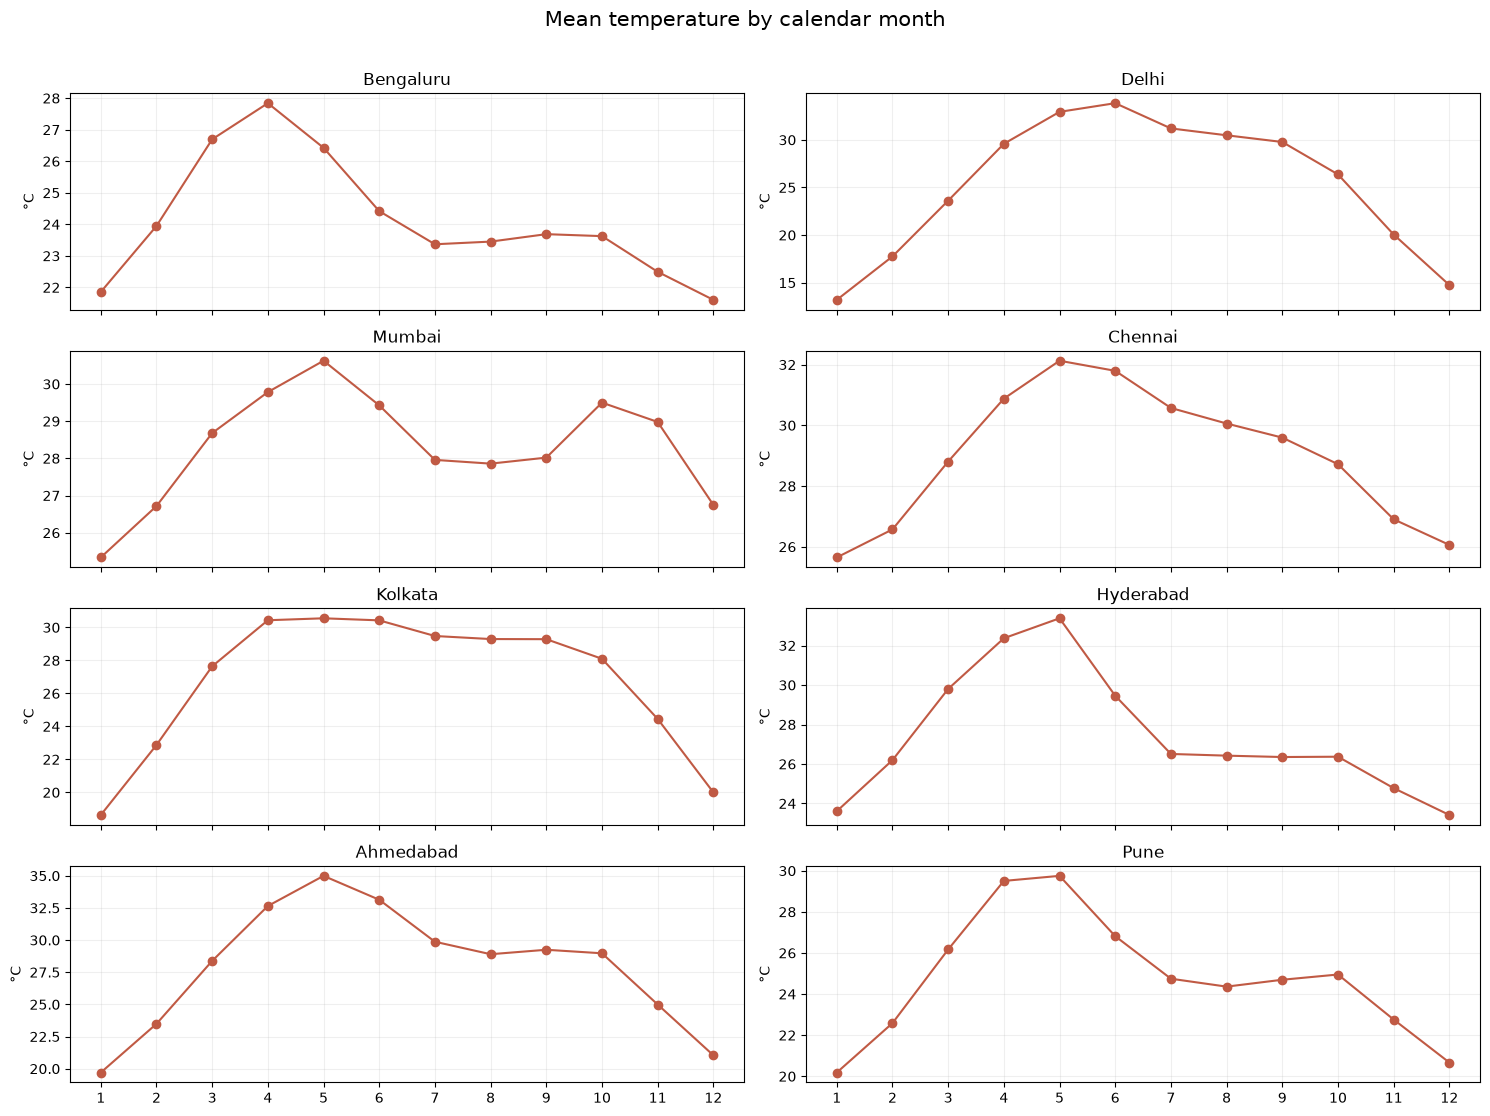

In [43]:
fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)
for ax, city in zip(axes.flat, CITY_NAMES):
    station = CITIES[city]["station"]
    frame = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{station}.csv", parse_dates=["date"])
    frame["month"] = frame["date"].dt.month
    monthly = frame.groupby("month")["temperature_c_interp"].mean()
    ax.plot(monthly.index, monthly.values, marker="o", lw=1.5, color="#c05a44")
    ax.set_title(city)
    ax.set_xticks(range(1, 13))
    ax.set_ylabel("°C")
    ax.grid(alpha=0.2)
fig.suptitle("Mean temperature by calendar month", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

**Interpretation.** Every location has an annual temperature cycle, but the level, amplitude, and daily variability differ. That makes absolute RMSE useful for comparing forecasting difficulty, while the gain over each city's persistence baseline measures improvement beyond simply using yesterday's temperature.

## 4. Trend, annual seasonality, stationarity, and correlograms (ACF and PACF)

The first-stage city pipeline computed STL trend/seasonal summaries, ADF and KPSS tests, and ACF values. ADF's null is a unit root; KPSS's null is stationarity, so agreement between them is informative because their null hypotheses differ.

In [44]:
pattern_rows = []
stationarity_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    dec, acf = b["decomposition"], b["acf"]
    raw = b["stationarity"]["raw"]
    stationarity_rows.append({
        "City": city,
        "ADF p": raw["adf"]["p_value"],
        "ADF supports stationarity": raw["adf"]["stationary"],
        "KPSS p": raw["kpss"]["p_value"],
        "KPSS supports stationarity": raw["kpss"]["stationary"],
        "Conclusion": raw["conclusion"],
    })
    pattern_rows.append({
        "City": city,
        "Linear trend (°C/decade)": dec["linear_slope_per_decade"],
        "STL trend change (°C)": dec["stl_trend_delta"],
        "Annual seasonal strength": dec["seasonal_strength"],
        "ACF lag 1": acf["lag1_raw"],
        "ACF lag 7": acf["acf_lag7_raw"],
        "ACF lag 365": acf["acf_lag365_raw"],
    })
stationarity_table = pd.DataFrame(stationarity_rows)
pattern_table = pd.DataFrame(pattern_rows)
display(pattern_table.round(3))
display(stationarity_table.round(5))

,City,Linear trend (°C/decade),STL trend change (°C),Annual seasonal strength,ACF lag 1,ACF lag 7,ACF lag 365
0,Bengaluru,0.187,0.304,0.800,0.923,0.768,0.717
1,Delhi,0.056,-0.919,0.933,0.979,0.923,0.909
2,Mumbai,0.581,-0.565,0.636,0.902,0.624,0.577
3,Chennai,0.772,0.939,0.836,0.940,0.807,0.791
4,Kolkata,0.453,-0.106,0.883,0.962,0.859,0.846
5,Hyderabad,-0.398,0.238,0.806,0.940,0.806,0.743
6,Ahmedabad,-0.245,-0.332,0.907,0.973,0.890,0.872
7,Pune,0.186,-0.119,0.851,0.954,0.827,0.802


,City,ADF p,ADF supports stationarity,KPSS p,KPSS supports stationarity,Conclusion
0,Bengaluru,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
1,Delhi,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
2,Mumbai,0.00000,True,0.07564,True,Stationary (ADF & KPSS agree)
3,Chennai,0.00028,True,0.10000,True,Stationary (ADF & KPSS agree)
4,Kolkata,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
5,Hyderabad,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
6,Ahmedabad,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
7,Pune,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)


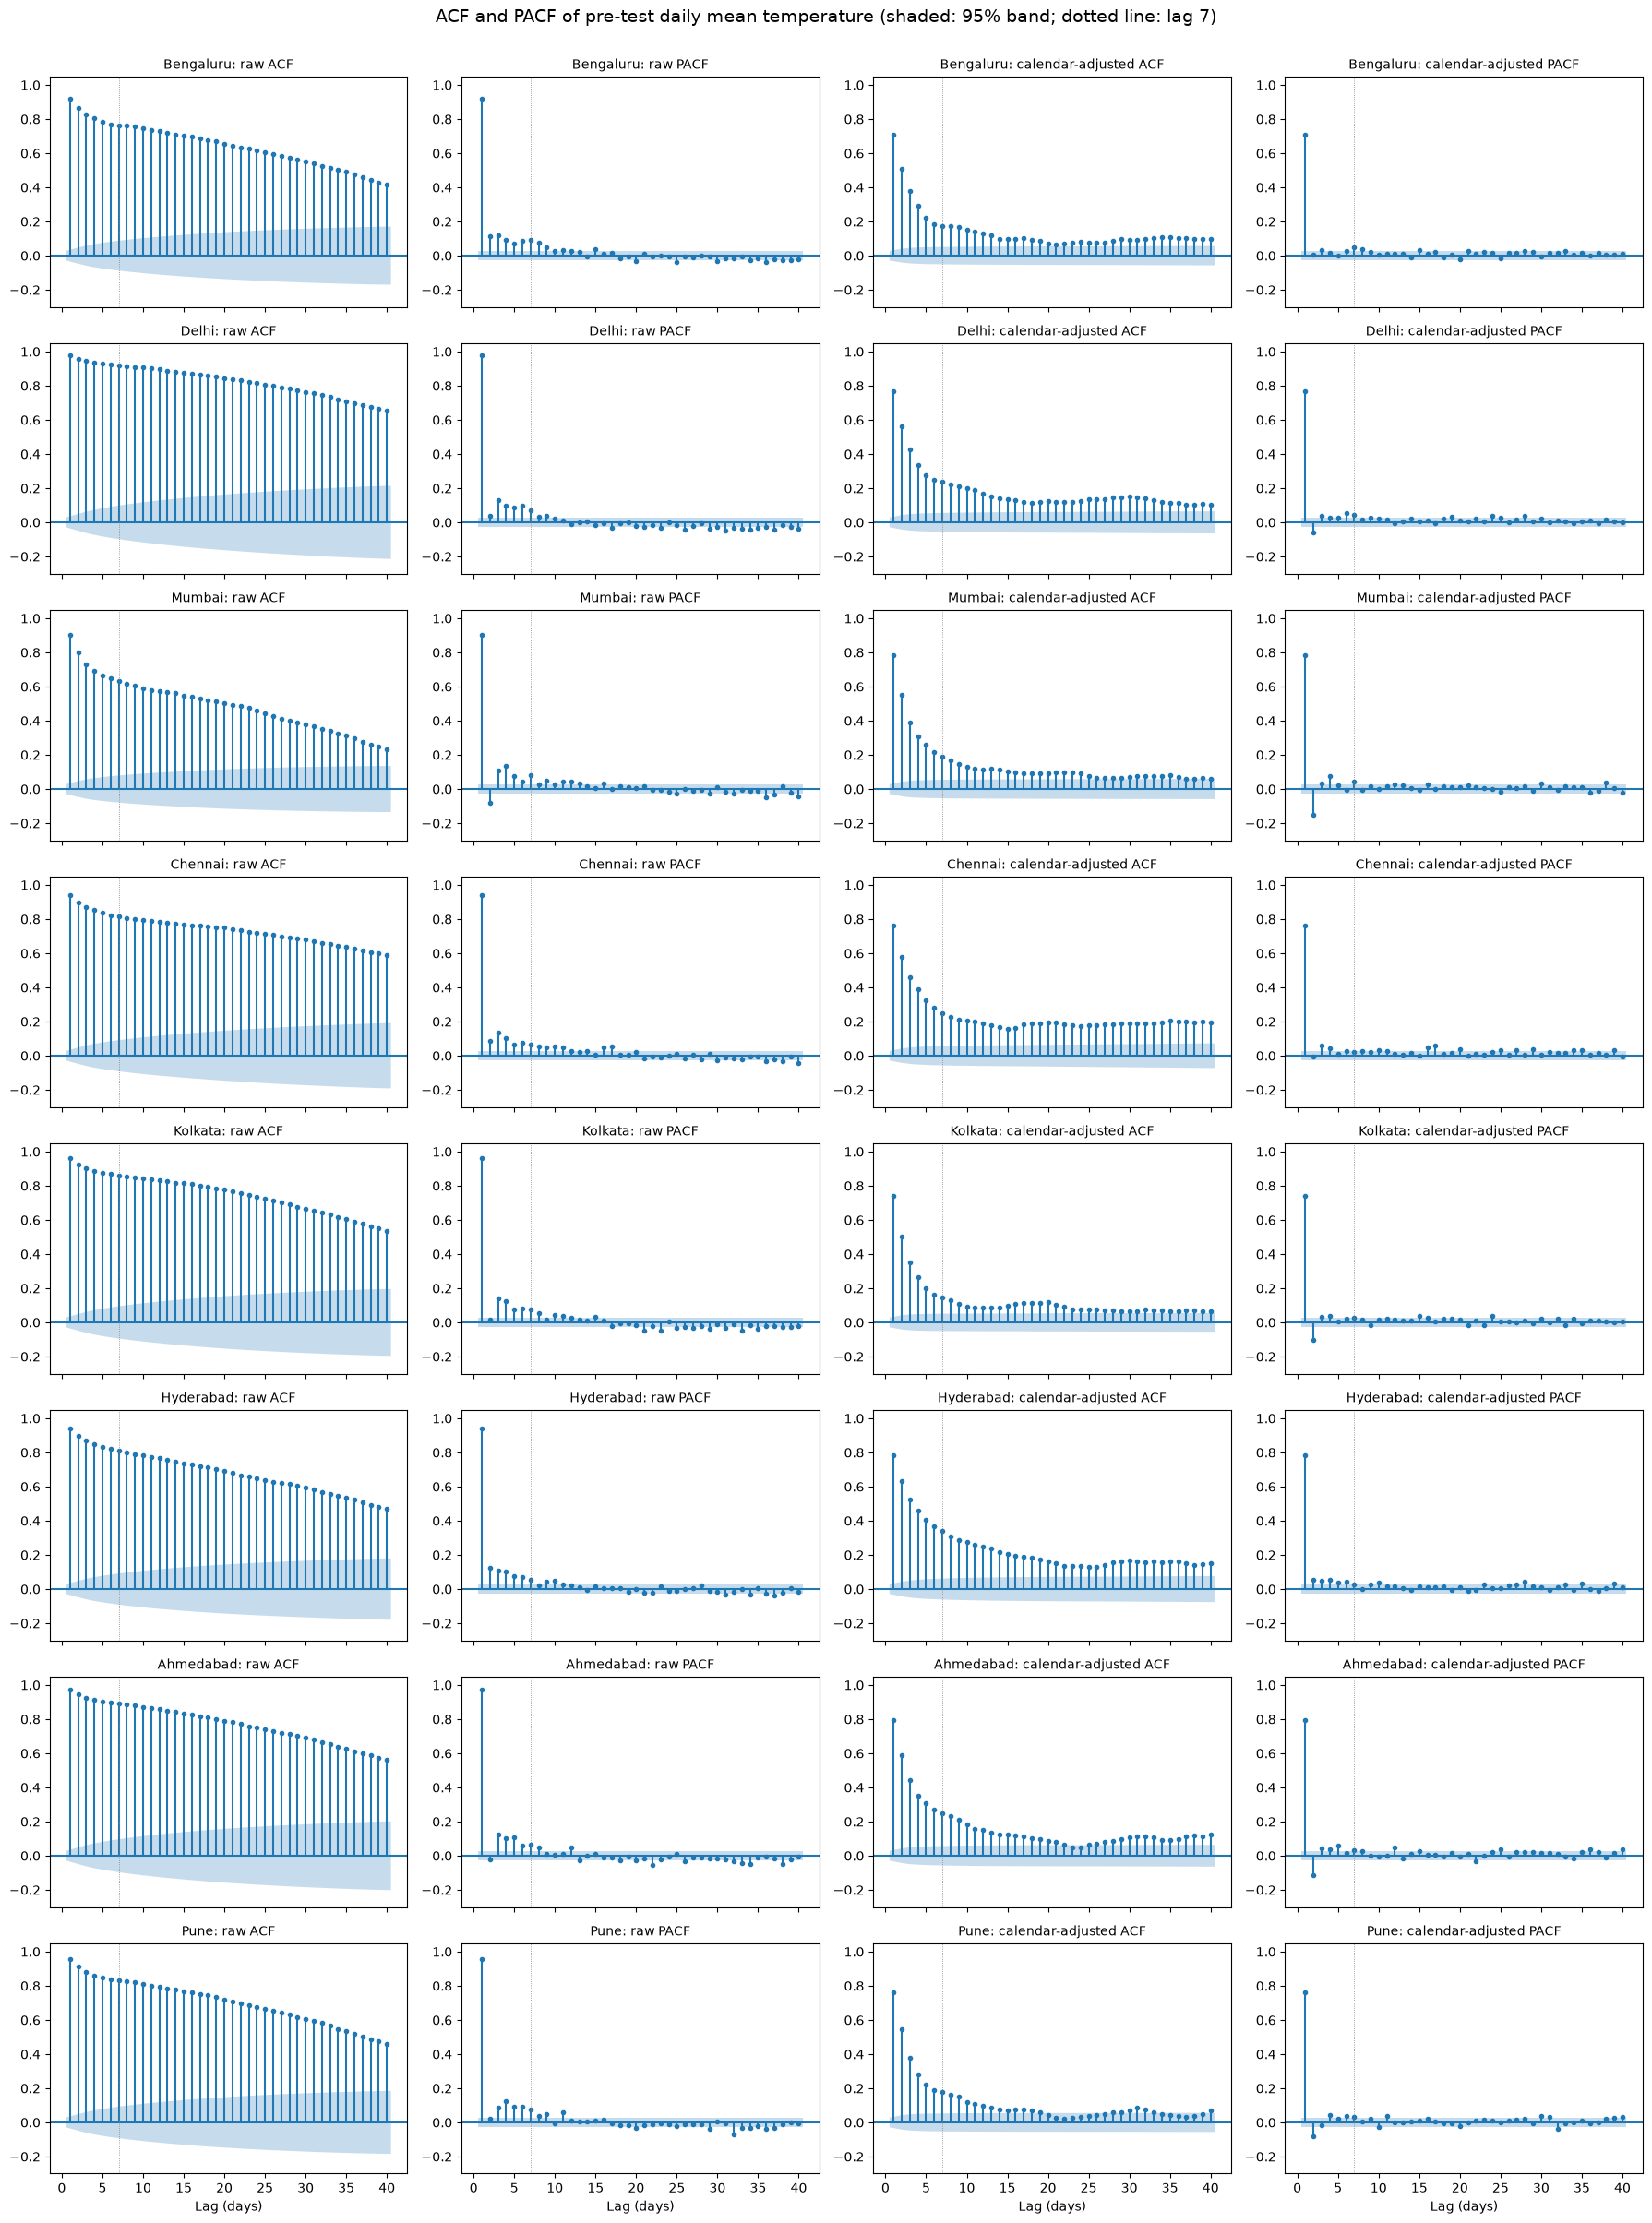

In [45]:
# ACF and PACF for all eight cities, computed on exactly the series used for order
# selection: the first 85% (pre-test history) of the interpolated daily mean temperature.
# Left pair: raw series (what ARIMA/SARIMA model). Right pair: the anomaly left after
# removing the annual and weekly Fourier calendar terms (what ARMAX/SARIMAX model).
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf as sm_acf, pacf as sm_pacf


def calendar_features(index):
    """Same deterministic annual (k = 1-3) and weekly Fourier terms as src/rubric_extension.py."""
    idx = pd.DatetimeIndex(index)
    annual = 2 * np.pi * (idx.dayofyear.to_numpy() - 1) / 365.25
    weekly = 2 * np.pi * np.arange(len(idx), dtype=float) / 7.0
    cols = [f(k * annual) for k in (1, 2, 3) for f in (np.sin, np.cos)]
    return np.column_stack(cols + [np.sin(weekly), np.cos(weekly)])


N_LAGS = 40
pre_test = {}
for city in CITY_NAMES:
    frame = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{CITIES[city]['station']}.csv",
                        parse_dates=["date"]).set_index("date")
    y = frame["temperature_c_interp"].to_numpy(dtype=float)
    y = y[: int(len(y) * 0.85)]
    X = np.column_stack([np.ones(len(y)), calendar_features(frame.index[: len(y)])])
    anomaly = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    pre_test[city] = {"raw": y, "anomaly": anomaly}

fig, axes = plt.subplots(len(CITY_NAMES), 4, figsize=(18, 3.0 * len(CITY_NAMES)), sharex=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for row, city in zip(axes, CITY_NAMES):
        for ax, kind, label, plotter in [
            (row[0], "raw", "raw ACF", plot_acf), (row[1], "raw", "raw PACF", plot_pacf),
            (row[2], "anomaly", "calendar-adjusted ACF", plot_acf),
            (row[3], "anomaly", "calendar-adjusted PACF", plot_pacf),
        ]:
            kwargs = {"method": "ywm"} if plotter is plot_pacf else {}
            plotter(pre_test[city][kind], lags=N_LAGS, zero=False, ax=ax, markersize=3, **kwargs)
            ax.set_title(f"{city}: {label}", fontsize=10)
            ax.set_ylim(-0.3, 1.05)
            ax.axvline(7, color="grey", lw=0.6, ls=":")
for ax in axes[-1]:
    ax.set_xlabel("Lag (days)")
fig.suptitle("ACF and PACF of pre-test daily mean temperature (shaded: 95% band; dotted line: lag 7)",
             y=1.002, fontsize=14)
fig.tight_layout()
plt.show()

In [46]:
# Numerical summary of the correlograms next to the BIC-selected orders from Section 6.
corr_rows = []
for city in CITY_NAMES:
    raw, anomaly = pre_test[city]["raw"], pre_test[city]["anomaly"]
    band = 1.96 / np.sqrt(len(raw))
    raw_acf, raw_pacf = sm_acf(raw, nlags=30, fft=True), sm_pacf(raw, nlags=30, method="ywm")
    an_acf, an_pacf = sm_acf(anomaly, nlags=30, fft=True), sm_pacf(anomaly, nlags=30, method="ywm")
    selection = ext_city[city]["information_criterion_order_selection"]
    corr_rows.append({
        "City": city,
        "Raw ACF lag 1 / 7 / 30": f"{raw_acf[1]:.2f} / {raw_acf[7]:.2f} / {raw_acf[30]:.2f}",
        "Raw PACF lag 1": raw_pacf[1],
        "Raw PACF max |lag 2-7|": np.abs(raw_pacf[2:8]).max(),
        "Adj. ACF lag 1 / 7 / 30": f"{an_acf[1]:.2f} / {an_acf[7]:.2f} / {an_acf[30]:.2f}",
        "Adj. PACF lag 1": an_pacf[1],
        "Adj. PACF lag 2": an_pacf[2],
        "Adj. PACF lag 7": an_pacf[7],
        "95% band (±)": band,
        "BIC ARIMA (p,d,q)": tuple(selection["ARIMA"]["selected"]["order"]),
        "BIC ARMAX (p,d,q)": tuple(selection["ARMAX"]["selected"]["order"]),
        "BIC SARIMA seasonal": tuple(selection["SARIMA"]["selected"]["seasonal_order"]),
    })
correlogram_table = pd.DataFrame(corr_rows)
display(correlogram_table.round(3))

,City,Raw ACF lag 1 / 7 / 30,Raw PACF lag 1,Raw PACF max |lag 2-7|,Adj. ACF lag 1 / 7 / 30,Adj. PACF lag 1,Adj. PACF lag 2,Adj. PACF lag 7,95% band (±),"BIC ARIMA (p,d,q)","BIC ARMAX (p,d,q)",BIC SARIMA seasonal
0,Bengaluru,0.92 / 0.76 / 0.55,0.921,0.121,0.71 / 0.17 / 0.09,0.710,0.006,0.049,0.029,"(1, 0, 2)","(1, 0, 0)","(0, 0, 1, 7)"
1,Delhi,0.98 / 0.92 / 0.76,0.978,0.131,0.77 / 0.24 / 0.15,0.767,-0.062,0.041,0.029,"(2, 0, 1)","(1, 0, 1)","(1, 0, 0, 7)"
2,Mumbai,0.90 / 0.63 / 0.38,0.904,0.135,0.78 / 0.19 / 0.07,0.782,-0.154,0.042,0.029,"(1, 0, 2)","(2, 0, 0)","(0, 0, 1, 7)"
3,Chennai,0.94 / 0.81 / 0.68,0.943,0.134,0.76 / 0.25 / 0.19,0.760,-0.003,0.024,0.029,"(2, 0, 1)","(2, 0, 2)","(0, 0, 0, 0)"
4,Kolkata,0.96 / 0.86 / 0.67,0.962,0.139,0.74 / 0.14 / 0.07,0.741,-0.102,0.028,0.029,"(2, 0, 2)","(1, 0, 1)","(1, 0, 0, 7)"
5,Hyderabad,0.94 / 0.81 / 0.60,0.941,0.126,0.78 / 0.34 / 0.17,0.781,0.053,0.029,0.029,"(2, 0, 1)","(1, 0, 2)","(0, 0, 1, 7)"
6,Ahmedabad,0.97 / 0.89 / 0.69,0.973,0.126,0.79 / 0.25 / 0.11,0.795,-0.115,0.035,0.029,"(2, 0, 2)","(1, 0, 1)","(0, 0, 1, 7)"
7,Pune,0.95 / 0.83 / 0.61,0.955,0.127,0.76 / 0.18 / 0.07,0.760,-0.080,0.035,0.029,"(2, 0, 2)","(2, 0, 0)","(0, 0, 1, 7)"


**Stationarity.** ADF rejects a unit root (p ≤ 0.0003) and KPSS does not reject stationarity (p ≥ 0.076) for every city, so all eight series are treated as level-stationary and **d = 0** is selected throughout. Stationarity does not imply that the series has no seasonality: the annual cycle is a deterministic, repeating mean pattern, not a stochastic trend.

**What the ACF shows.** On the raw series the ACF decays slowly — about 0.90–0.98 at lag 1 and still 0.58–0.91 at lag 365 (table above) — and never cuts off. That slow, smooth decay is the signature of an autoregressive process combined with the deterministic annual cycle, not of a short moving-average process, so a pure MA model is ruled out.

**What the PACF shows.** The raw PACF has one dominant spike at lag 1 (0.90–0.98) and then drops abruptly to values no larger than about 0.14 in absolute value. Those later spikes often lie outside the 95% band, but with roughly 4,650 pre-test days the band is only ±0.029, so they are statistically detectable yet small. Most of that residual structure is the unmodelled annual cycle: once the Fourier calendar terms are removed (right-hand panels), the PACF is a clear **cut-off after lag 1–2** (adjusted PACF at lag 1 = 0.71–0.80; at lag 2 between −0.15 and +0.05) while the adjusted ACF decays geometrically (lag 7 = 0.14–0.34, lag 30 = 0.07–0.19).

**How the plots support the selected orders (Section 6).**

- *AR order p.* A PACF cut-off after lag 1–2 with a tailing ACF identifies an AR(1)–AR(2) core. Every BIC-selected order has p ∈ {1, 2}, matching that pattern.
- *Calendar-adjusted (ARMAX/SARIMAX) orders.* Where the adjusted PACF has a clear negative lag-2 value — Mumbai (−0.15), Ahmedabad (−0.12) and Pune (−0.08) — BIC adds a second AR term (ARMAX and SARIMAX (2,0,0) for Mumbai and Pune; SARIMAX (2,0,0) for Ahmedabad). Bengaluru, whose adjusted PACF is flat after lag 1 (lag 2 ≈ 0.01), is selected as (1,0,0). Kolkata and Delhi also have a negative lag-2 PACF (−0.10 and −0.06), which one MA term reproduces as well as a second AR term, so BIC picks (1,0,1). Hyderabad has the slowest short-lag decay of the adjusted ACF (lag 7 = 0.34) with a positive lag-2 PACF, which BIC fits with two MA terms, (1,0,2). Chennai (2,0,2) is the one case where BIC keeps more terms than the PACF alone would suggest; its adjusted ACF also decays most slowly (lag 30 = 0.19).
- *Why ARIMA needs more terms than ARMAX.* Without calendar regressors, the AR/MA terms must also mimic the slow seasonal persistence visible in the raw ACF, so the raw-series ARIMA orders are larger, (1,0,2) to (2,0,2), and their BIC values are higher than the ARMAX ones.
- *Seasonal weekly terms.* The PACF at lag 7 is small — at most about 0.05 after calendar adjustment — so weekly seasonal AR/MA terms (m = 7) are at most marginal. That is consistent with SARIMA improving BIC only slightly over ARIMA and with SARIMA and ARIMA having near-identical test RMSE (1.038 vs 1.037 °C on average, Section 7).

## 5. Stage A: baselines, fixed-order ARIMA, LSTM/Transformer, and multi-horizon forecasts

The base pipeline (`src/run_all_cities.py`) uses a chronological 70/15/15 train/validation/test split, a 30-day input window, and a common held-out period (2022-10-02 to 2024-12-31, 822 days). LSTM and Transformer preprocessing is fit on training data only. Its ARIMA benchmark uses a **fixed** order, ARIMA(2,0,2), for every city, chosen before any per-city order selection was done.

Stage A's one-step table below is kept for traceability. The one-step model ranking used for conclusions is the Stage B comparison in Section 7, which includes the selected ARIMA-family orders and the additional model families. Stage A is the **only** source for the direct 1/7/14/21/30-day horizon comparison.

In [47]:
one_step_rows = []
horizon_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    summary = next(row for row in base["cities_ranked_by_best_one_step_rmse"] if row["city"] == city)
    one_step_rows.append({
        "City": city,
        "Persistence MAE": summary["persistence_mae"],
        "ARIMA(2,0,2) MAE": summary["arima_2_0_2_mae"],
        "LSTM MAE": summary["lstm_mae"],
        "Transformer MAE": summary["transformer_mae"],
        "Stage A best (by RMSE)": summary["best_one_step_model"],
        "Stage A best RMSE": summary["best_one_step_rmse"],
        "Transformer skill vs persistence (%)": summary["transformer_skill_vs_persistence_mae_pct"],
    })
    mh = b["multi_horizon"]
    row = {"City": city}
    for model in ("Persistence", "Seasonal naive (365)", "LSTM", "Transformer"):
        row[f"{model} mean-horizon MAE"] = float(np.mean([mh[model][str(h)]["mae"] for h in mh["horizons"]]))
    row["Transformer mean-horizon skill (%)"] = summary["transformer_horizon_skill_pct"]
    horizon_rows.append(row)
base_forecast_table = pd.DataFrame(one_step_rows).sort_values("Stage A best RMSE")
horizon_table = pd.DataFrame(horizon_rows)
display(Markdown("**Stage A one-step results (fixed-order ARIMA; superseded for ranking by Section 7)**"))
display(base_forecast_table.round(3))
display(Markdown("**Stage A direct multi-horizon results (mean MAE over 1, 7, 14, 21, 30 days)**"))
display(horizon_table.round(3))

**Stage A one-step results (fixed-order ARIMA; superseded for ranking by Section 7)**

,City,Persistence MAE,"ARIMA(2,0,2) MAE",LSTM MAE,Transformer MAE,Stage A best (by RMSE),Stage A best RMSE,Transformer skill vs persistence (%)
0,Bengaluru,0.668,0.638,0.650,0.655,"ARIMA(2, 0, 2)",0.829,1.898
2,Mumbai,0.637,0.619,0.617,0.637,LSTM,0.858,0.011
3,Chennai,0.649,0.626,0.630,0.631,Transformer,0.858,2.741
7,Pune,0.748,0.747,0.741,0.743,Transformer,0.976,0.644
6,Ahmedabad,0.778,0.766,0.792,0.765,Transformer,1.044,1.652
5,Hyderabad,0.818,0.817,0.826,0.818,Transformer,1.090,0.018
4,Kolkata,0.922,0.913,0.952,0.956,"ARIMA(2, 0, 2)",1.221,-3.665
1,Delhi,1.051,1.048,1.102,1.044,Transformer,1.367,0.662


**Stage A direct multi-horizon results (mean MAE over 1, 7, 14, 21, 30 days)**

,City,Persistence mean-horizon MAE,Seasonal naive (365) mean-horizon MAE,LSTM mean-horizon MAE,Transformer mean-horizon MAE,Transformer mean-horizon skill (%)
0,Bengaluru,1.282,1.400,1.179,1.108,13.537
1,Delhi,2.777,2.643,2.313,1.929,30.550
2,Mumbai,1.441,1.543,1.290,1.241,13.886
3,Chennai,1.255,1.213,1.082,1.019,18.778
4,Kolkata,2.160,2.107,1.914,1.721,20.348
5,Hyderabad,1.777,2.019,1.670,1.566,11.847
6,Ahmedabad,2.016,2.039,1.878,1.655,17.893
7,Pune,1.634,1.816,1.506,1.429,12.572


**Onestep Mae**

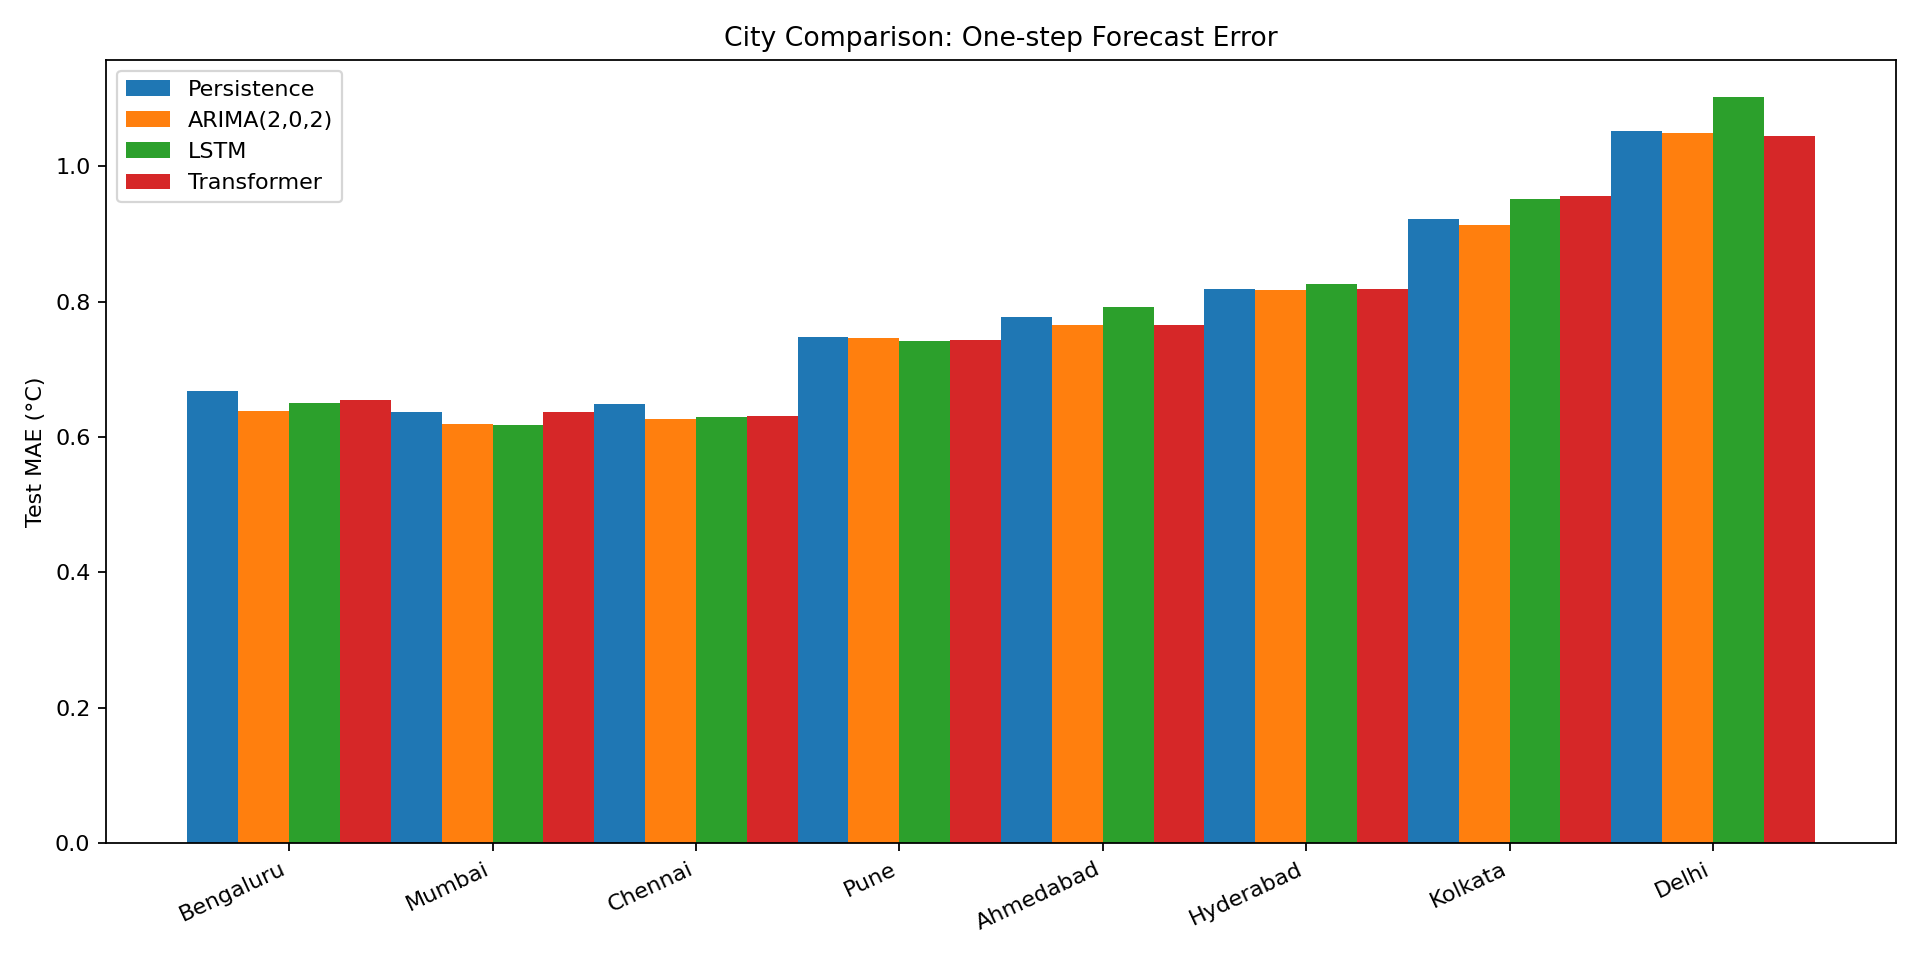

**Transformer Horizon Mae**

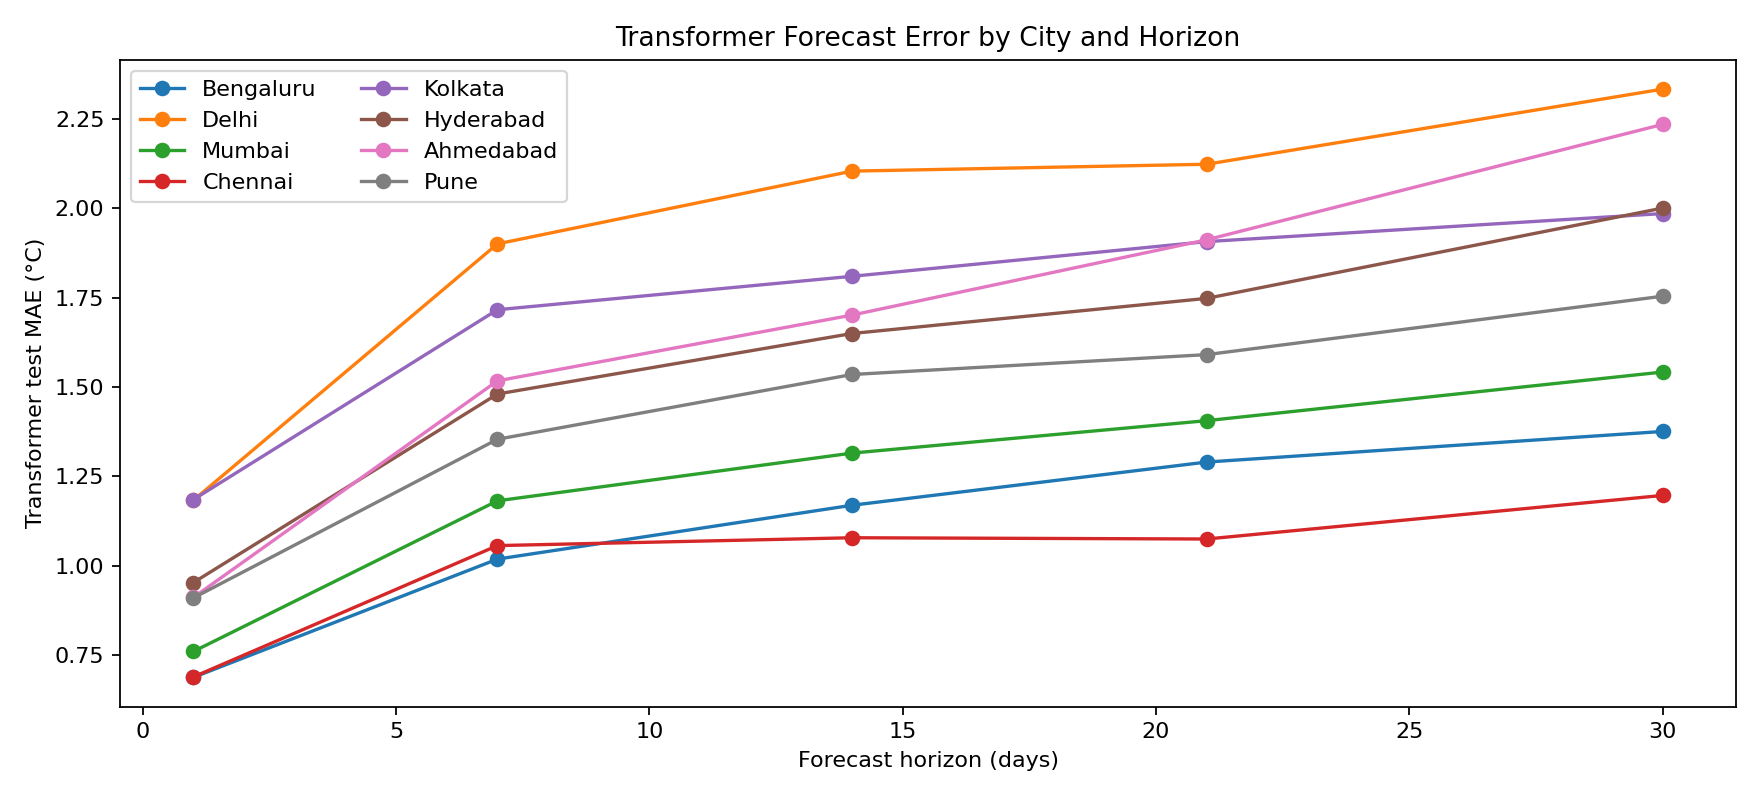

**Skill Vs Persistence**

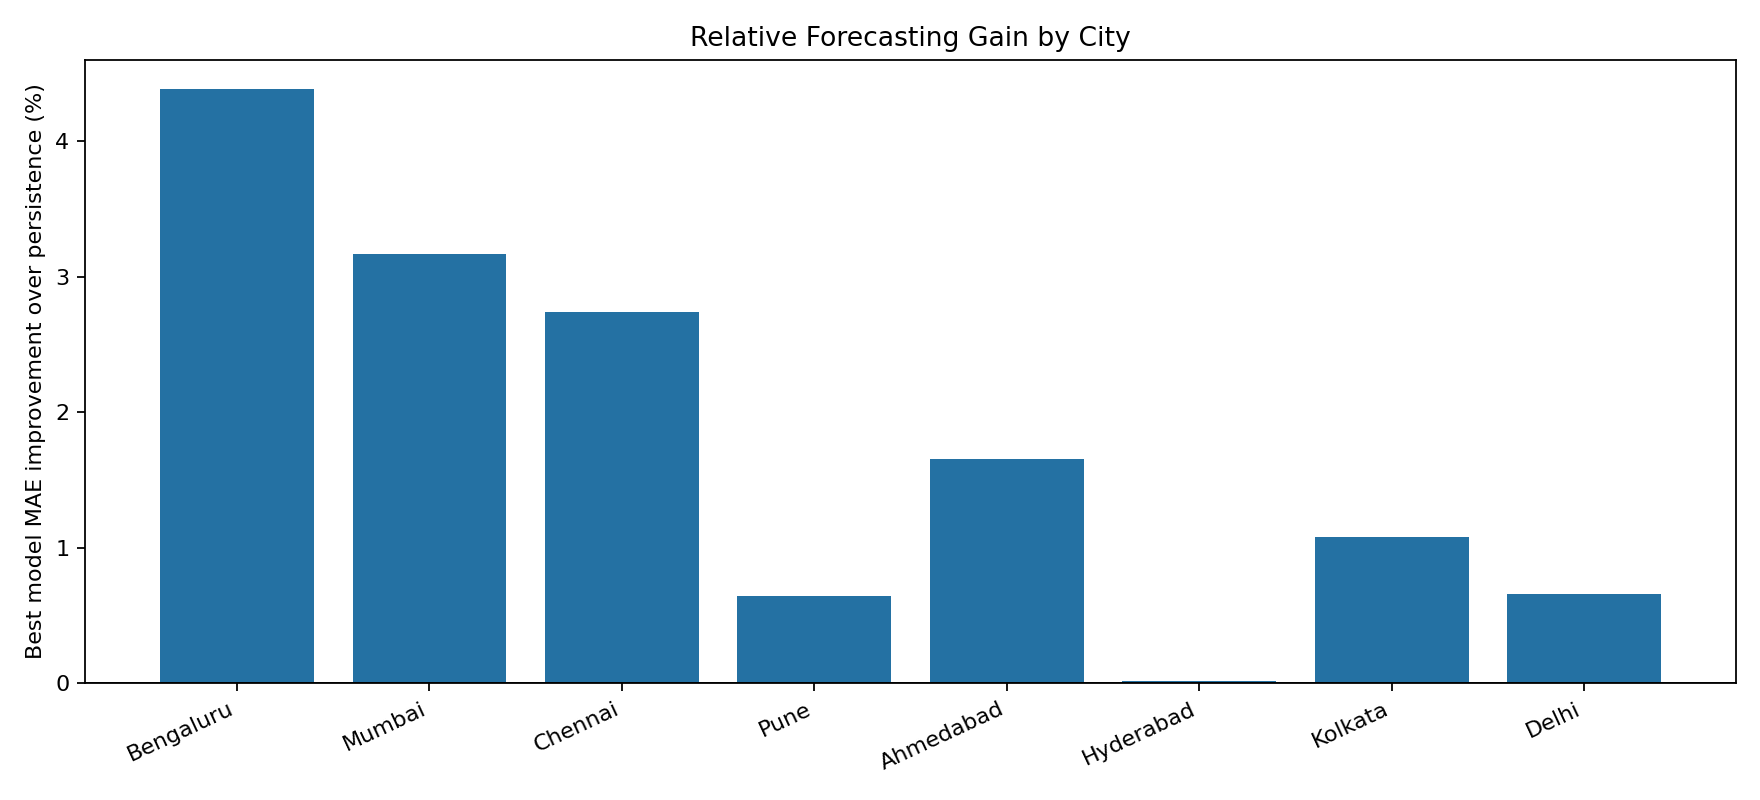

In [48]:
for filename in ("onestep_mae.png", "transformer_horizon_mae.png", "skill_vs_persistence.png"):
    display(Markdown(f"**{filename.replace('_', ' ').replace('.png', '').title()}**"))
    display(Image(filename=str(ROOT / "figures" / "city_comparison" / filename)))

**Baseline interpretation.** Persistence is a strong next-day reference for a highly autocorrelated series (raw ACF at lag 1 = 0.90–0.98). In Stage A the LSTM and Transformer improve on persistence MAE by at most 3.2% at one step, and both are worse than persistence in Kolkata (Transformer by 3.7%). The picture changes with horizon: persistence degrades quickly, and the Transformer's mean-horizon MAE is 11.8–30.6% lower than persistence in all eight cities. A model can therefore have low absolute error yet add little over persistence, so the notebook reports both city-level error and relative skill.

## 6. ARIMA, SARIMA, ARMAX, and SARIMAX order selection (Stage B)

Stage A's fixed ARIMA(2,0,2) is replaced here by per-city information-criterion selection.

- **d:** ADF and KPSS are applied to the first 85% of each city's series. The first differencing value for which both tests support stationarity is selected; here we retain the recorded test evidence rather than assume a common d. All eight cities give d = 0 (Section 4).
- **p and q:** The ACF/PACF in Section 4 point to an AR(1)–AR(2) core with possibly one or two MA terms, so the grid p, q ∈ {0, 1, 2} brackets every plausible order. Candidate AIC/BIC values and convergence flags are stored for every city and family.
- **P, D, Q, m:** Seasonal models test weekly seasonal AR/MA terms with m = 7 and D = 0. Seasonal variants are tested around the leading nonseasonal p/q candidates ranked by AIC and BIC. The annual cycle (m = 365) is too long for a seasonal ARMA term at daily resolution and is handled by Fourier regressors instead.
- Both AIC and BIC winners are reported. **BIC-selected orders** supply the one-step forecasts in the main model comparison; the final test period is not used for order selection.
- ARMAX/SARIMAX regressors are deterministic, known-ahead annual and weekly Fourier calendar terms. No future observed weather values are used.

In [49]:
order_rows = []
candidate_rows = []
for city in CITY_NAMES:
    selection = ext_city[city]["information_criterion_order_selection"]
    d = selection["d_selection"]["selected_d"]
    correlogram = selection["d_selection"]["tests"][-1].get("correlogram", {})
    for family in ("ARIMA", "SARIMA", "ARMAX", "SARIMAX"):
        fit = selection[family]
        bic, aic = fit["selected"], fit["selected_by_aic"]
        order_rows.append({
            "City": city, "Selected d": d, "Family": family,
            "BIC order (p,d,q)": tuple(bic["order"]),
            "BIC seasonal (P,D,Q,m)": tuple(bic["seasonal_order"]),
            "BIC": bic["bic"],
            "AIC order (p,d,q)": tuple(aic["order"]),
            "AIC seasonal (P,D,Q,m)": tuple(aic["seasonal_order"]),
            "AIC": aic["aic"],
            "Candidates": fit["candidate_count"],
            "Valid candidates": fit["valid_candidate_count"],
            "ACF q hint": correlogram.get("initial_q_hint"),
            "PACF p hint": correlogram.get("initial_p_hint"),
        })
        for candidate in fit["candidates"]:
            if candidate.get("bic") is not None:
                candidate_rows.append({"City": city, "Family": family, **candidate})
orders = pd.DataFrame(order_rows)
candidates = pd.DataFrame(candidate_rows)
display(orders.round(3))
print(f"Candidate fits with finite AIC/BIC: {len(candidates)}")

,City,Selected d,Family,"BIC order (p,d,q)","BIC seasonal (P,D,Q,m)",BIC,"AIC order (p,d,q)","AIC seasonal (P,D,Q,m)",AIC,Candidates,Valid candidates,ACF q hint,PACF p hint
0,Bengaluru,0,ARIMA,"(1, 0, 2)","(0, 0, 0, 0)",11699.905,"(1, 0, 2)","(0, 0, 0, 0)",11667.678,9,9,3,3
1,Bengaluru,0,SARIMA,"(1, 0, 2)","(0, 0, 1, 7)",11686.675,"(1, 0, 2)","(0, 0, 1, 7)",11648.011,15,15,3,3
2,Bengaluru,0,ARMAX,"(1, 0, 0)","(0, 0, 0, 0)",11392.418,"(1, 0, 0)","(0, 0, 0, 0)",11321.513,9,9,3,3
3,Bengaluru,0,SARIMAX,"(1, 0, 0)","(0, 0, 1, 7)",11383.783,"(1, 0, 1)","(0, 0, 1, 7)",11305.300,15,15,3,3
4,Delhi,0,ARIMA,"(2, 0, 1)","(0, 0, 0, 0)",17008.979,"(2, 0, 1)","(0, 0, 0, 0)",16976.751,9,9,3,3
5,Delhi,0,SARIMA,"(2, 0, 1)","(1, 0, 0, 7)",16991.886,"(2, 0, 1)","(1, 0, 0, 7)",16953.221,15,15,3,3
6,Delhi,0,ARMAX,"(1, 0, 1)","(0, 0, 0, 0)",16673.658,"(1, 0, 1)","(0, 0, 0, 0)",16596.309,9,9,3,3
7,Delhi,0,SARIMAX,"(1, 0, 1)","(0, 0, 1, 7)",16651.997,"(1, 0, 1)","(0, 0, 1, 7)",16568.223,15,15,3,3
8,Mumbai,0,ARIMA,"(1, 0, 2)","(0, 0, 0, 0)",11917.054,"(1, 0, 2)","(0, 0, 0, 0)",11884.826,9,9,3,3
9,Mumbai,0,SARIMA,"(1, 0, 2)","(0, 0, 1, 7)",11901.574,"(1, 0, 2)","(0, 0, 1, 7)",11862.910,18,18,3,3


Candidate fits with finite AIC/BIC: 393


In [50]:
# Inspect the three lowest-BIC candidates for each city/family; all candidates remain in `candidates`.
top_candidates = (candidates.sort_values("bic")
                  .groupby(["City", "Family"], as_index=False, sort=False)
                  .head(3))
display(top_candidates[["City", "Family", "order", "seasonal_order", "aic", "bic", "converged"]].round(2))

,City,Family,order,seasonal_order,aic,bic,converged
195,Chennai,SARIMAX,"[2, 0, 2]","[0, 0, 1, 7]",11124.84,11221.50,True
189,Chennai,SARIMAX,"[1, 0, 0]","[0, 0, 1, 7]",11150.74,11228.07,False
191,Chennai,SARIMAX,"[1, 0, 0]","[1, 0, 1, 7]",11151.23,11235.01,True
179,Chennai,ARMAX,"[2, 0, 2]","[0, 0, 0, 0]",11149.15,11239.39,True
174,Chennai,ARMAX,"[1, 0, 0]","[0, 0, 0, 0]",11175.81,11246.72,True
...,...,...,...,...,...,...,...
65,Delhi,SARIMA,"[2, 0, 2]","[0, 0, 0, 0]",16926.30,16964.97,False
70,Delhi,SARIMA,"[2, 0, 1]","[1, 0, 0, 7]",16953.22,16991.89,True
69,Delhi,SARIMA,"[2, 0, 1]","[0, 0, 1, 7]",16955.09,16993.75,False
55,Delhi,ARIMA,"[2, 0, 1]","[0, 0, 0, 0]",16976.75,17008.98,True


**Interpretation.** The BIC-selected orders agree with the correlogram identification in Section 4: every selected p is 1 or 2, matching the PACF cut-off after lag 1–2, and adding calendar regressors lowers BIC by 121–335 points (Bengaluru, for example: ARIMA 11,700 vs ARMAX 11,392) while shrinking the needed ARMA order, which is what the calendar-adjusted correlograms predicted. AIC, which penalises parameters less, picks the same order as BIC in 26 of the 32 city–family fits; in the other six it keeps one or two extra MA/AR or seasonal terms (largest difference: Mumbai and Ahmedabad ARMAX, where AIC picks (2,0,2)). In-sample BIC does not guarantee the best test error: for Bengaluru the BIC-selected ARIMA(1,0,2) has a test RMSE of 0.836 °C against 0.829 °C for Stage A's fixed ARIMA(2,0,2). Both orders are reported rather than tuning on the test set.

## 7. Stage B: all model families and accuracy comparison

Holt-Winters models use additive annual seasonality (period 365), with and without a damped trend. Random Forest and Gradient Boosting use lagged temperatures and calendar features. LSTM and Transformer use the base sequence setup. All one-step forecasts are evaluated on the same test dates with MAE, RMSE, MASE, R², and bias. Lower MAE/RMSE/MASE is better; higher R² is better.

### 7.1 Family ranking and per-city leaders

In [51]:
family_summary = pd.DataFrame(extension["models_ranked_by_mean_city_rmse"])
display(family_summary.round(3))

best_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    for model, metrics in result["model_metrics"].items():
        best_rows.append({"City": city, "Model": model, **metrics})
all_model_scores = pd.DataFrame(best_rows)
display(all_model_scores.sort_values(["City", "rmse"])
        .groupby("City", as_index=False, sort=False).head(3)
        [["City", "Model", "mae", "rmse", "mase", "r2", "bias_actual_minus_predicted"]].round(3))

,model,mean_mae,mean_rmse,mean_mase,mean_r2,cities_won_by_rmse,mean_rmse_rank
0,ARMAX,0.763,1.016,0.935,0.894,2,1.750
1,SARIMAX,0.763,1.016,0.935,0.894,3,2.000
2,RandomForest,0.777,1.027,0.952,0.893,2,3.875
3,GradientBoosting,0.776,1.029,0.949,0.893,1,3.750
4,Transformer,0.781,1.037,0.955,0.890,0,5.875
5,ARIMA,0.774,1.037,0.946,0.890,0,5.750
6,SARIMA,0.775,1.038,0.947,0.890,0,6.375
7,LSTM,0.789,1.051,0.960,0.889,0,6.750
8,Persistence (t-1),0.784,1.071,0.960,0.882,0,8.875
9,Holt-Winters damped,0.859,1.146,1.053,0.865,0,10.125


,City,Model,mae,rmse,mase,r2,bias_actual_minus_predicted
84,Ahmedabad,SARIMAX,0.724,1.015,0.846,0.947,-0.077
85,Ahmedabad,ARMAX,0.726,1.016,0.848,0.947,-0.077
86,Ahmedabad,GradientBoosting,0.761,1.041,0.889,0.944,-0.110
0,Bengaluru,SARIMAX,0.656,0.826,0.982,0.870,0.144
1,Bengaluru,ARMAX,0.656,0.826,0.983,0.870,0.146
2,Bengaluru,LSTM,0.650,0.834,0.973,0.868,0.044
42,Chennai,GradientBoosting,0.621,0.845,1.021,0.863,0.047
43,Chennai,ARMAX,0.628,0.845,1.032,0.862,0.091
44,Chennai,SARIMAX,0.628,0.846,1.032,0.862,0.092
14,Delhi,SARIMAX,1.005,1.338,0.891,0.966,-0.112


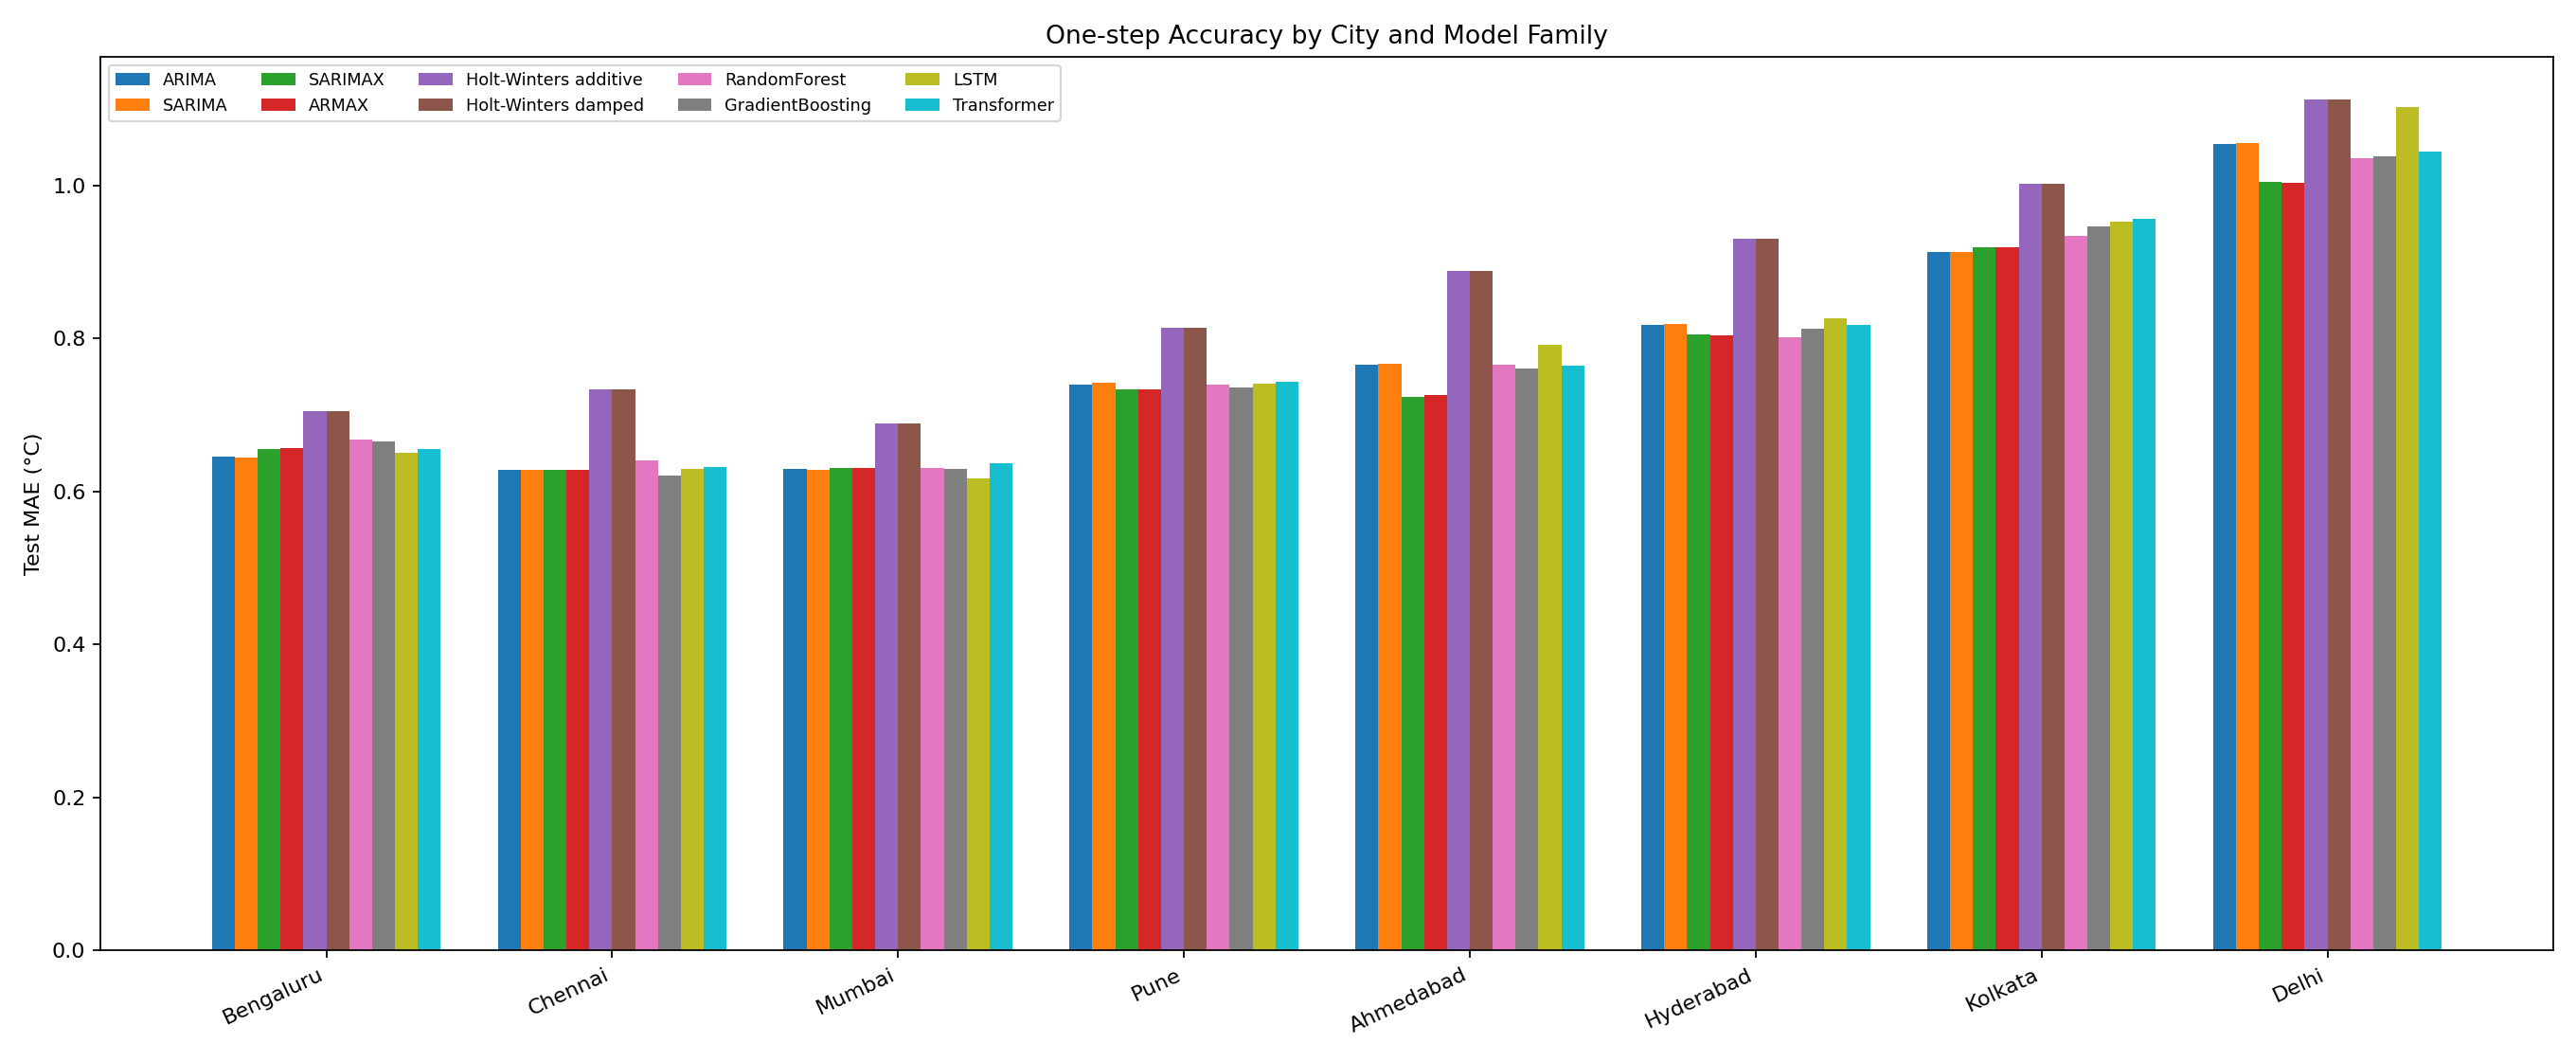

In [52]:
display(Image(filename=str(ROOT / "figures" / "rubric_extension" / "all_models_city_mae.png")))

### 7.2 Reconciling the Stage A and Stage B comparisons

Stage A (Section 5) and Stage B (this section) report different "best one-step model" labels for the same city — for example, Stage A names the Transformer for Delhi while Stage B names SARIMAX. This is not a contradiction. The check below shows that:

1. both pipelines use the same 822 test dates;
2. the six models they share (persistence, two seasonal-naive baselines, climatology, LSTM, Transformer) have **identical** test MAE and RMSE in both result files — the two pipelines produce the same forecasts for those models; and
3. Stage A's "best" is chosen from a smaller candidate set. When Stage A's fixed ARIMA(2,0,2) is added to Stage B's 14 models, the overall RMSE winner is the Stage B winner in every city.

In [53]:
shared = ["Persistence (t-1)", "Seasonal naive (t-7)", "Seasonal naive (t-365)",
          "Mean (climatology)", "LSTM", "Transformer"]
rec_rows = []
for city in CITY_NAMES:
    a_scores = {**base_city[city]["onestep"]["baselines"], **base_city[city]["onestep"]["models"]}
    b_scores = ext_city[city]["model_metrics"]
    same_dates = (base_city[city]["forecast_setup"]["test_start"], base_city[city]["forecast_setup"]["test_end"]) \
        == tuple(ext_city[city]["test_period"])
    max_diff = max(max(abs(a_scores[m]["mae"] - b_scores[m]["mae"]), abs(a_scores[m]["rmse"] - b_scores[m]["rmse"]))
                   for m in shared)
    pooled = {m: s["rmse"] for m, s in b_scores.items()}
    pooled["ARIMA(2,0,2) fixed (Stage A)"] = a_scores["ARIMA(2, 0, 2)"]["rmse"]
    pooled_best = min(pooled, key=pooled.get)
    a_best = base_city[city]["onestep"]["best"]
    b_best = min(b_scores, key=lambda m: b_scores[m]["rmse"])
    rec_rows.append({
        "City": city,
        "Same test dates": same_dates,
        "Test days (A / B)": f"{base_city[city]['forecast_setup']['n_test_seq']} / {ext_city[city]['n_test']}",
        "Max |Δ| shared MAE/RMSE": max_diff,
        "Stage A best": a_best, "Stage A best RMSE": a_scores[a_best]["rmse"],
        "Stage B best": b_best, "Stage B best RMSE": b_scores[b_best]["rmse"],
        "Fixed ARIMA(2,0,2) RMSE": a_scores["ARIMA(2, 0, 2)"]["rmse"],
        "BIC ARIMA RMSE": b_scores["ARIMA"]["rmse"],
        "Pooled best (A ∪ B)": pooled_best,
    })
reconciliation = pd.DataFrame(rec_rows)
display(reconciliation.round(4))
assert reconciliation["Same test dates"].all()
assert (reconciliation["Max |Δ| shared MAE/RMSE"] < 1e-9).all()
assert (reconciliation["Pooled best (A ∪ B)"] == reconciliation["Stage B best"]).all()
print("Shared models agree exactly across pipelines; the pooled winner equals the Stage B winner in all cities.")

,City,Same test dates,Test days (A / B),Max |Δ| shared MAE/RMSE,Stage A best,Stage A best RMSE,Stage B best,Stage B best RMSE,"Fixed ARIMA(2,0,2) RMSE",BIC ARIMA RMSE,Pooled best (A ∪ B)
0,Bengaluru,True,822 / 822,0.0,"ARIMA(2, 0, 2)",0.8288,SARIMAX,0.8258,0.8288,0.8363,SARIMAX
1,Delhi,True,822 / 822,0.0,Transformer,1.3675,SARIMAX,1.3378,1.3733,1.3793,SARIMAX
2,Mumbai,True,822 / 822,0.0,LSTM,0.8583,RandomForest,0.8504,0.8591,0.8689,RandomForest
3,Chennai,True,822 / 822,0.0,Transformer,0.8585,GradientBoosting,0.8450,0.8622,0.8654,GradientBoosting
4,Kolkata,True,822 / 822,0.0,"ARIMA(2, 0, 2)",1.2213,ARMAX,1.2083,1.2213,1.2214,ARMAX
5,Hyderabad,True,822 / 822,0.0,Transformer,1.0898,RandomForest,1.0648,1.0941,1.0948,RandomForest
6,Ahmedabad,True,822 / 822,0.0,Transformer,1.0440,SARIMAX,1.0147,1.0487,1.0490,SARIMAX
7,Pune,True,822 / 822,0.0,Transformer,0.9757,ARMAX,0.9631,0.9982,0.9836,ARMAX


Shared models agree exactly across pipelines; the pooled winner equals the Stage B winner in all cities.


**How to read the two pipelines.** Stage B is the definitive one-step comparison because it contains every Stage A one-step model except the fixed ARIMA(2,0,2), and that model never wins the pooled comparison. Stage A's labels differ only because its candidate set had no calendar-regressor ARIMA models and no tree models. The fixed ARIMA(2,0,2) and the BIC-selected ARIMA differ by at most about 0.015 °C RMSE in any city (Pune: 0.998 vs 0.984 °C), so replacing the placeholder order changed the ARIMA results only marginally; the gain came from adding calendar regressors (ARMAX/SARIMAX). One caveat on metric choice: ranking by MAE instead of RMSE can change a close call — for Bengaluru the fixed ARIMA(2,0,2) has the lowest MAE (0.638 °C) although SARIMAX has the lowest RMSE. Stage A's multi-horizon results answer a different question (direct forecasts up to 30 days ahead) and are not superseded by Stage B.

### 7.3 Paired model comparison

A paired Diebold–Mariano test compares each model's daily absolute loss with that city's persistence forecast. A Newey–West/HAC variance estimate uses 30 lags, and Holm correction controls the family-wise error across model comparisons within each city. A non-significant result is not proof that two models are equivalent.

In [54]:
dm_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    best_model = min(result["model_metrics"], key=lambda m: result["model_metrics"][m]["rmse"])
    for model, test in result["diebold_mariano_absolute_loss_vs_persistence"].items():
        dm_rows.append({"City": city, "Model": model,
                        "Mean absolute-loss difference vs persistence": test["mean_abs_loss_difference"],
                        "Holm-adjusted p": test.get("holm_adjusted_p_value"),
                        "Significant at 0.05": test.get("significant_at_0_05"),
                        "Selected best model": model == best_model})
dm_table = pd.DataFrame(dm_rows)
display(dm_table[dm_table["Selected best model"]].round(4))

,City,Model,Mean absolute-loss difference vs persistence,Holm-adjusted p,Significant at 0.05,Selected best model
6,Bengaluru,SARIMAX,-0.0117,1.0000,False,True
19,Delhi,SARIMAX,-0.0468,0.0062,True,True
35,Mumbai,RandomForest,-0.0064,1.0000,False,True
49,Chennai,GradientBoosting,-0.0285,0.0107,True,True
57,Kolkata,ARMAX,-0.0030,1.0000,False,True
74,Hyderabad,RandomForest,-0.0163,1.0000,False,True
84,Ahmedabad,SARIMAX,-0.0537,0.0001,True,True
96,Pune,ARMAX,-0.0145,1.0000,False,True


**Interpretation.** The selected best model has a lower mean absolute loss than persistence in all eight cities, but the reductions are small (0.003–0.054 °C per day). After Holm correction they are statistically significant only for Ahmedabad (−0.054 °C, p = 0.0001), Delhi (−0.047 °C, p = 0.006) and Chennai (−0.029 °C, p = 0.011). For the other five cities the test cannot distinguish the best model from persistence at one-step-ahead. Because the HAC variance allows for autocorrelated loss differentials, these conclusions remain valid despite the residual autocorrelation reported in Section 8.

## 8. Residual analysis

Residuals are actual minus forecast on the 822 test days, for the model with the lowest RMSE in each city. The table reports bias (with a t-statistic), Durbin–Watson, Ljung–Box at lags 10 and 30, and Jarque–Bera together with the residual skewness and excess kurtosis behind it. It also gives the share of residuals beyond ±1.96 SD in each tail, which shows what non-normality means for prediction intervals. A Ljung–Box rejection means serial dependence remains (predictable structure the model missed); a Jarque–Bera rejection means the error distribution is not Gaussian.

In [55]:
from scipy import stats

residual_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    best_model = min(result["model_metrics"], key=lambda m: result["model_metrics"][m]["rmse"])
    diag = result["residual_diagnostics"][best_model]
    resid = np.asarray(result["test_residuals"][best_model], dtype=float)
    sd = resid.std(ddof=1)
    centred = resid - resid.mean()
    resid_acf = sm_acf(resid, nlags=30, fft=True)
    lb30_fail = sum(d["ljung_box_lag30_p"] < 0.05 for d in result["residual_diagnostics"].values())
    residual_rows.append({
        "City": city, "Selected model": best_model,
        "Mean (°C)": diag["mean"], "Bias t": diag["mean"] / (sd / np.sqrt(len(resid))),
        "SD (°C)": diag["std"],
        "Durbin–Watson": diag["durbin_watson"],
        "Resid. ACF lag 1": resid_acf[1],
        "Max |resid. ACF| lags 1–30": np.abs(resid_acf[1:]).max(),
        "Ljung–Box lag-10 p": diag["ljung_box_lag10_p"],
        "Ljung–Box lag-30 p": diag["ljung_box_lag30_p"],
        "Models failing LB-30 (of 14)": lb30_fail,
        "Jarque–Bera stat": diag["jarque_bera_stat"],
        "Jarque–Bera p": diag["jarque_bera_p"],
        "Skewness": stats.skew(resid),
        "Excess kurtosis": stats.kurtosis(resid),
        "% below −1.96 SD": 100 * np.mean(centred < -1.96 * sd),
        "% above +1.96 SD": 100 * np.mean(centred > 1.96 * sd),
    })
residual_table = pd.DataFrame(residual_rows)
display(residual_table.round(3))
print(f"Residual-ACF 95% band for n = {len(resid)}: ±{1.96 / np.sqrt(len(resid)):.3f}; "
      f"Bonferroni threshold for 8 Ljung–Box tests: {0.05 / 8:.5f}")

,City,Selected model,Mean (°C),Bias t,SD (°C),Durbin–Watson,Resid. ACF lag 1,Max |resid. ACF| lags 1–30,Ljung–Box lag-10 p,Ljung–Box lag-30 p,Models failing LB-30 (of 14),Jarque–Bera stat,Jarque–Bera p,Skewness,Excess kurtosis,% below −1.96 SD,% above +1.96 SD
0,Bengaluru,SARIMAX,0.144,5.074,0.814,1.941,-0.003,0.090,0.024,0.020,9,49.347,0.0,-0.500,0.662,3.650,1.338
1,Delhi,SARIMAX,-0.112,-2.410,1.334,1.927,0.029,0.103,0.058,0.048,13,114.558,0.0,-0.560,1.446,3.893,1.460
2,Mumbai,RandomForest,0.069,2.328,0.848,1.661,0.164,0.164,0.001,0.005,13,154.124,0.0,-0.381,1.979,3.406,2.676
3,Chennai,GradientBoosting,0.047,1.594,0.844,1.900,0.047,0.097,0.144,0.051,8,233.674,0.0,-0.635,2.282,4.258,1.825
4,Kolkata,ARMAX,0.205,4.938,1.191,1.742,0.101,0.101,0.063,0.080,10,383.510,0.0,-0.761,2.980,3.771,1.825
5,Hyderabad,RandomForest,0.015,0.413,1.065,1.789,0.104,0.106,0.158,0.037,7,154.557,0.0,-0.647,1.685,3.771,1.460
6,Ahmedabad,SARIMAX,-0.077,-2.185,1.012,1.886,0.051,0.071,0.259,0.301,9,531.998,0.0,-0.677,3.701,3.406,1.582
7,Pune,ARMAX,0.059,1.755,0.962,1.933,0.030,0.094,0.002,0.006,13,93.297,0.0,-0.142,1.626,2.676,2.190


Residual-ACF 95% band for n = 822: ±0.068; Bonferroni threshold for 8 Ljung–Box tests: 0.00625


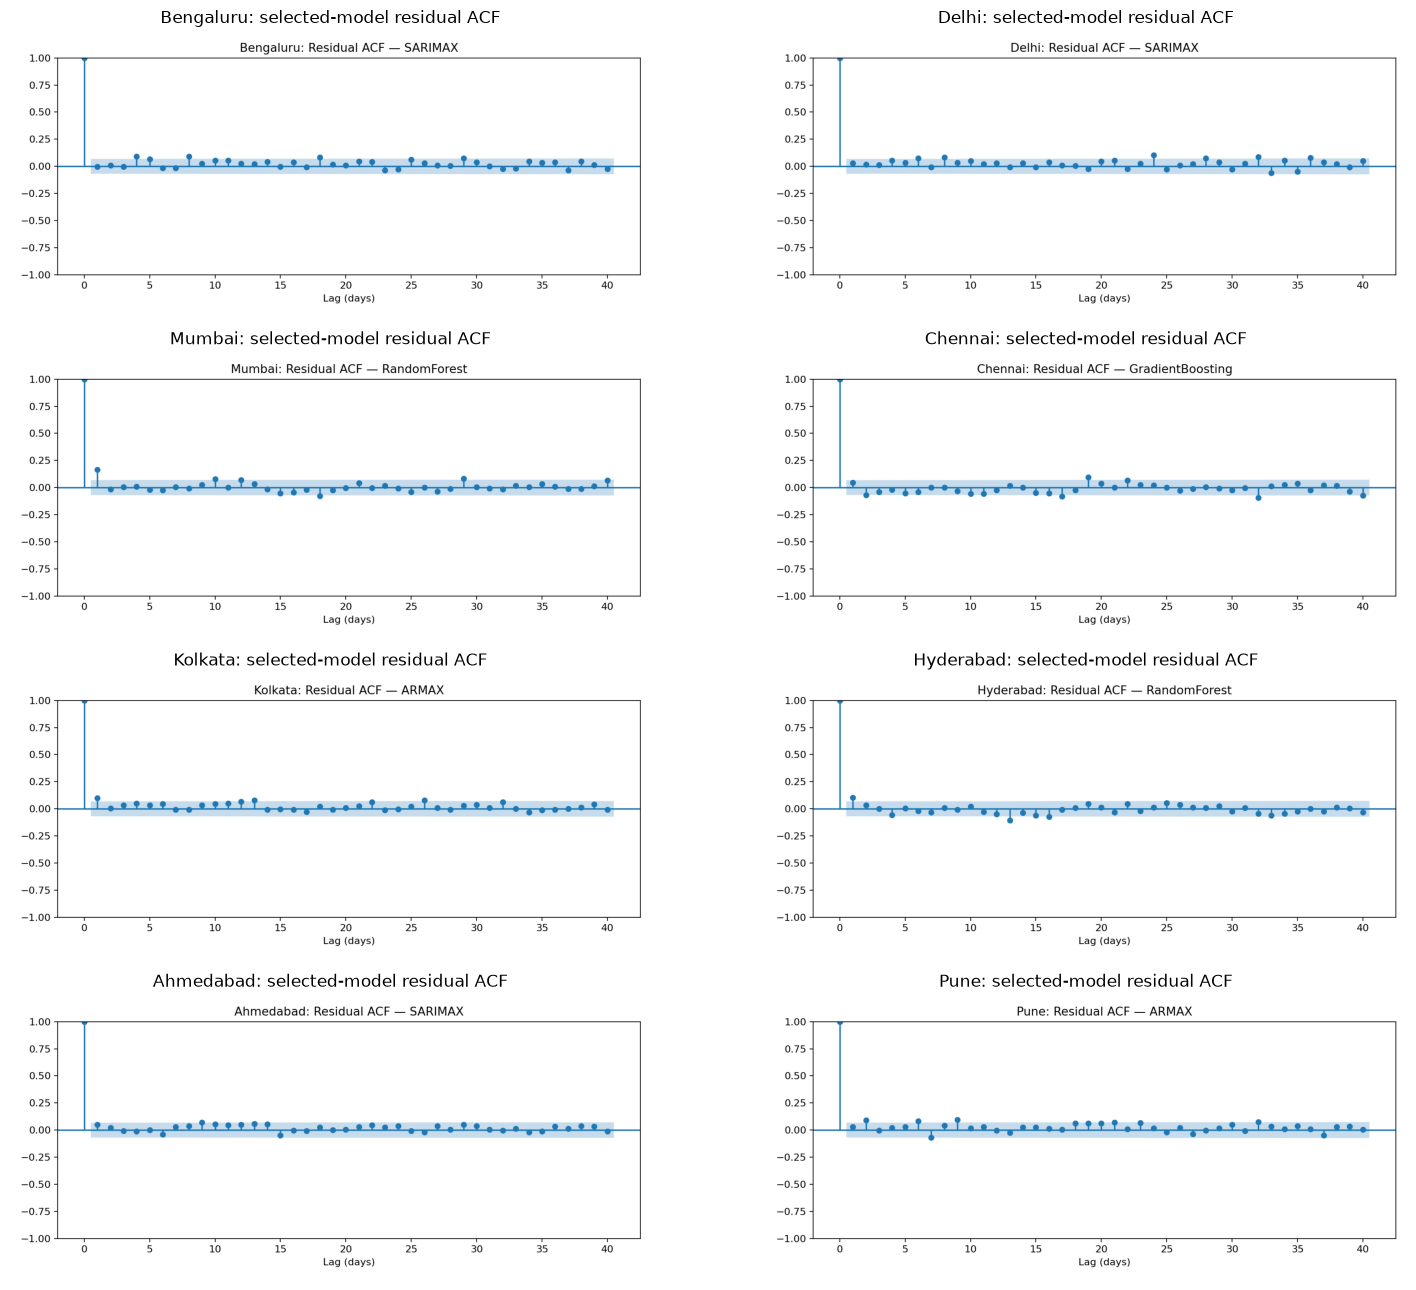

In [56]:
fig, axes = plt.subplots(4, 2, figsize=(16, 13))
for ax, city in zip(axes.flat, CITY_NAMES):
    path = ROOT / "figures" / "rubric_extension" / city.lower() / "best_model_residual_acf.png"
    ax.imshow(plt.imread(path))
    ax.set_title(f"{city}: selected-model residual ACF")
    ax.axis("off")
fig.tight_layout()
plt.show()

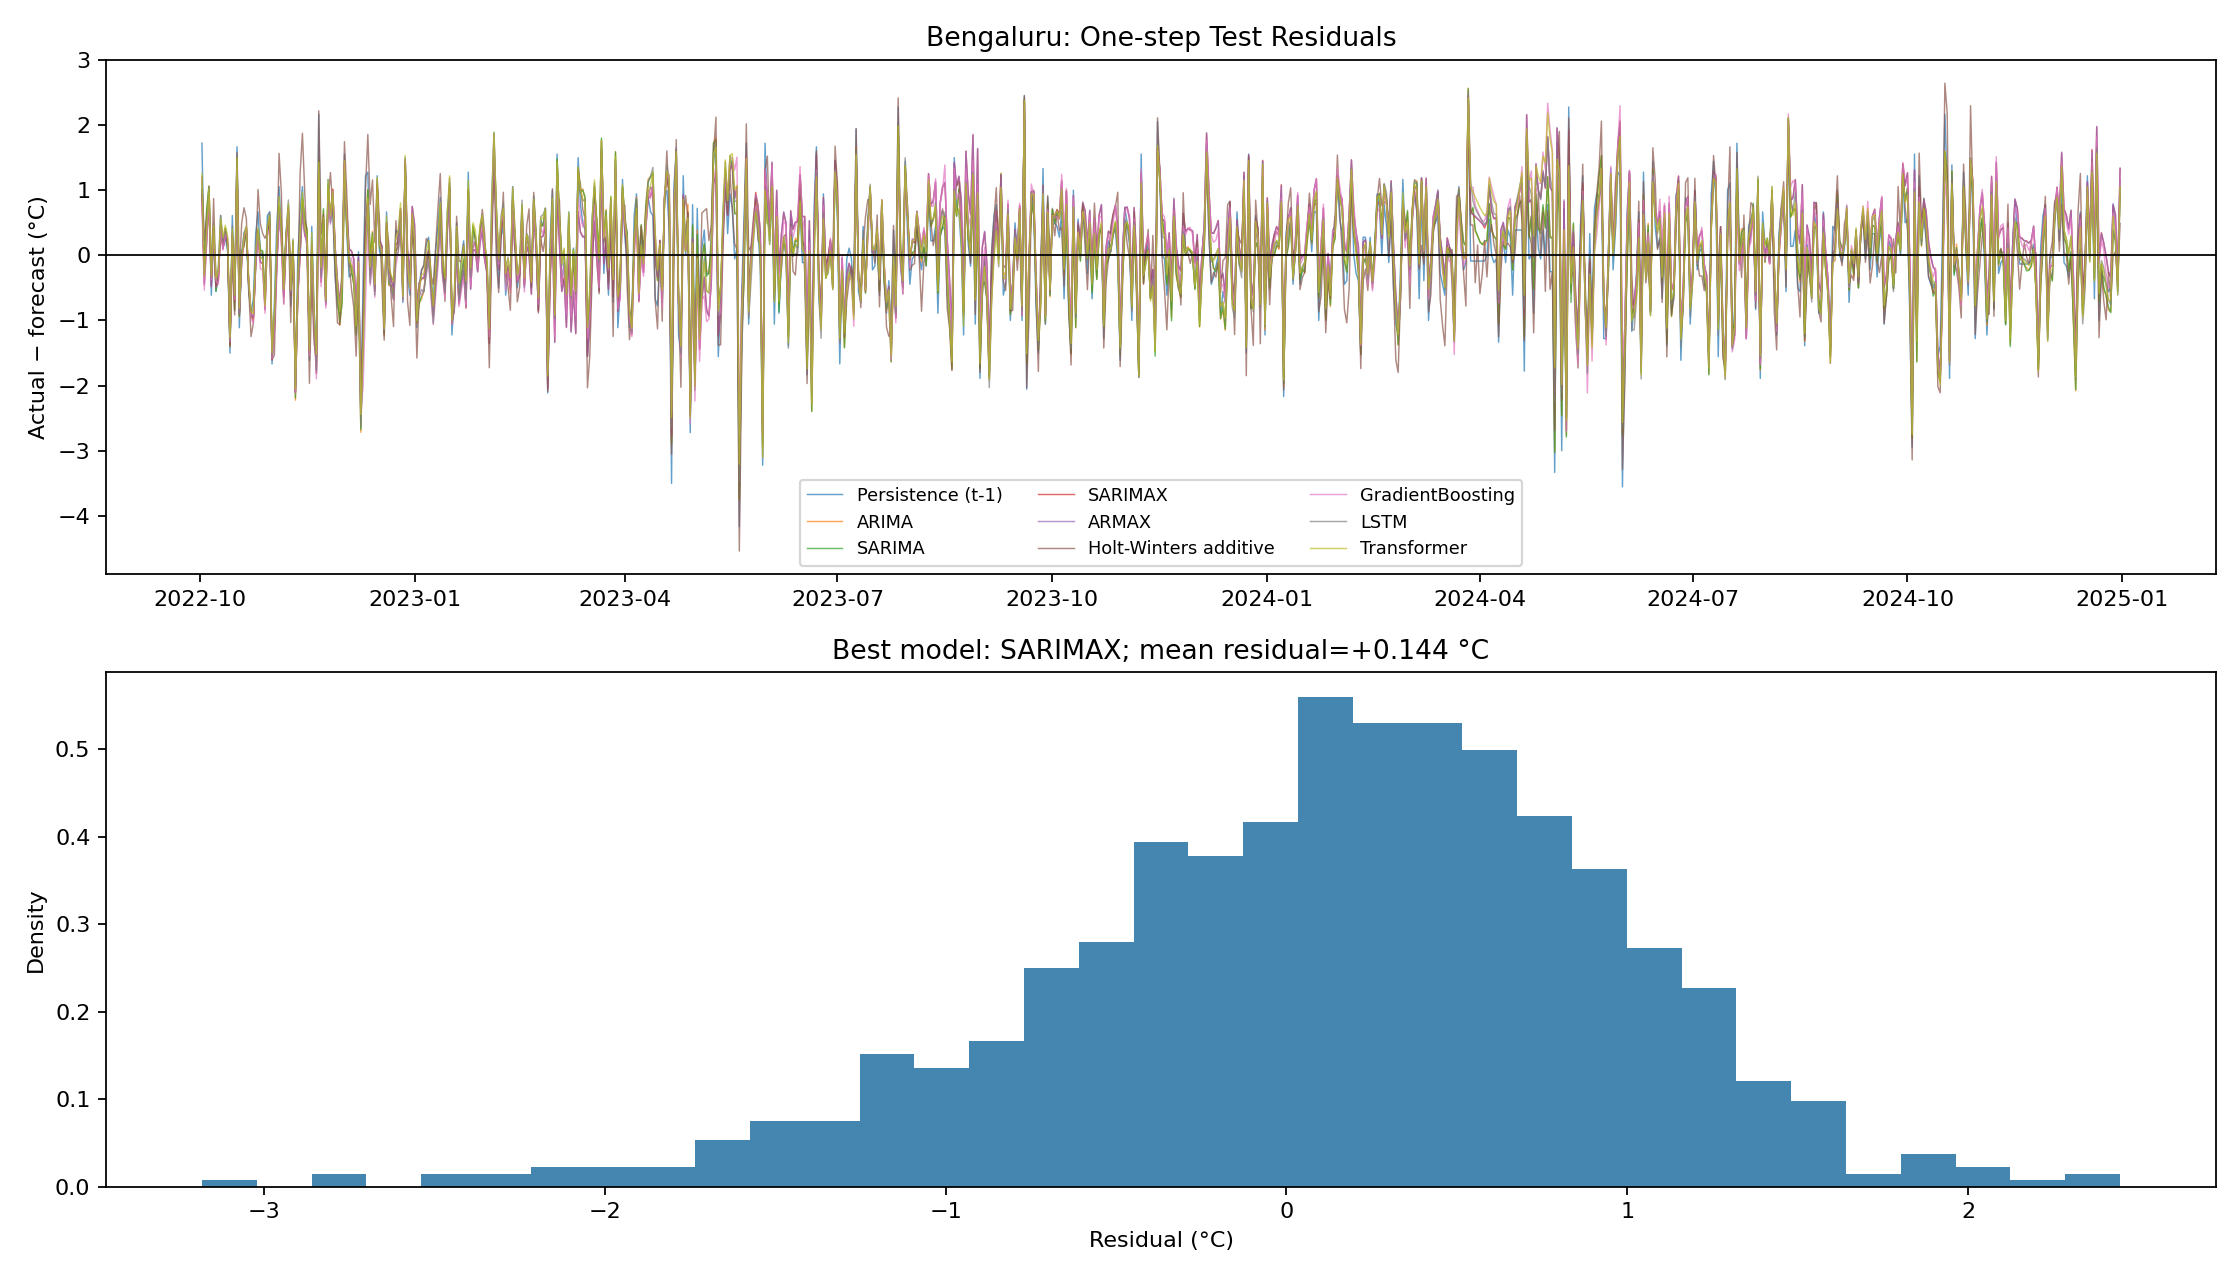

In [57]:
display(Image(filename=str(ROOT / "figures" / "rubric_extension" / "bengaluru" / "residual_diagnostics.png")))

**Interpretation of the residual diagnostics.**

*Bias.* Mean residuals range from −0.11 to +0.21 °C, small next to residual SDs of 0.81–1.33 °C. Two biases are clearly non-zero (|t| ≈ 5): Bengaluru (+0.14 °C) and Kolkata (+0.21 °C). In both cities the model systematically under-forecasts the 2022–2024 test period, which is consistent with a level shift that a model fitted on 2010–2022 does not track. Re-estimating the intercept on recent data or adding a simple bias correction would remove most of it.

*Ljung–Box (serial dependence).* At lag 30, five of the eight selected models reject white-noise residuals at the 5% level: Mumbai (p = 0.005), Pune (0.006), Bengaluru (0.020), Hyderabad (0.037) and Delhi (0.048). Chennai (0.051) and Kolkata (0.080) are borderline, and Ahmedabad (0.301) passes clearly. Two points limit how much this matters:

- With eight cities tested, a Bonferroni threshold of 0.05/8 ≈ 0.006 leaves only Mumbai and Pune as clear rejections. They also have by far the smallest lag-10 p-values (0.001 and 0.002; Bengaluru is next at 0.024).
- The size of the leftover dependence is small. The largest residual autocorrelation over lags 1–30 is 0.07–0.16, against a 95% band of ±0.068, so most rejections come from many small autocorrelations rather than one large missed pattern. The exception is Mumbai's Random Forest, with lag-1 residual autocorrelation 0.16 (Durbin–Watson 1.66): a tree model has no error-feedback (MA) term, so it leaves some day-to-day carry-over of its own errors. Kolkata and Hyderabad show a weaker version of the same pattern (lag-1 residual autocorrelation about 0.10; DW 1.74 and 1.79).

Residual autocorrelation is common across model types: per city, 7–13 of the 14 models fail Ljung–Box at lag 30. So it reflects weather dynamics that none of these univariate models captures — for example monsoon onset or the passage of western disturbances — rather than a defect of a particular selected model. In practical terms the remaining predictability is modest, which matches the small one-step gains over persistence in Section 7.

*Jarque–Bera (normality).* Normality is rejected decisively in every city (JB statistics 49–532, all p < 10⁻¹⁰). The departure has a consistent shape: negative skewness (−0.14 to −0.76) and excess kurtosis (0.7–3.7). Large errors are therefore mostly over-forecasts (actual much colder than predicted), consistent with abrupt cooling from rain or cold-air outbreaks that a one-step univariate model cannot anticipate. Ahmedabad (excess kurtosis 3.7) and Kolkata (3.0) have the heaviest tails.

*Consequences.*

1. **Point accuracy is unaffected.** MAE, RMSE and MASE do not assume normal or independent errors, and the Diebold–Mariano tests in Section 7.3 use HAC variance, so the model rankings stand.
2. **Symmetric Gaussian intervals are miscalibrated.** A ±1.96 SD band would contain about 95% of test residuals overall, but the misses are lopsided: 2.7–4.3% fall below the band and only 1.3–2.7% above it, against 2.5% per tail under normality. Empirical-quantile or bootstrapped residual intervals should be used for uncertainty statements, especially for cold-side risk.
3. **Remaining dependence suggests where to improve.** For Mumbai and Pune, the two clear Ljung–Box rejections, the logical next steps are to model the leftover error autocorrelation (for example an ARMA correction on the Random Forest's residuals in Mumbai) and to add exogenous predictors such as humidity, rainfall and wind. A higher AR order alone is unlikely to help much, because BIC already rejected larger orders on the training data.

## 9. Research conclusion

The cell below collects the numbers that the conclusion is based on.

In [58]:
from scipy.stats import spearmanr

ranked = extension["cities_ranked_by_best_model_rmse"]
daily_change = {}
for city in CITY_NAMES:
    temps = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{CITIES[city]['station']}.csv")["temperature_c_interp"]
    daily_change[city] = float(temps.diff().abs().mean())
conclusion_rows = []
for row in ranked:
    city = row["city"]
    dm = ext_city[city]["diebold_mariano_absolute_loss_vs_persistence"][row["best_model"]]
    summary_a = next(r for r in base["cities_ranked_by_best_one_step_rmse"] if r["city"] == city)
    conclusion_rows.append({
        "City": city, "Best one-step model": row["best_model"],
        "Best RMSE (°C)": row["best_rmse"], "Persistence RMSE (°C)": row["persistence_rmse"],
        "RMSE gain vs persistence (%)": 100 * (1 - row["best_rmse"] / row["persistence_rmse"]),
        "MAE gain vs persistence (%)": row["best_skill_vs_persistence_pct"],
        "DM significant (Holm)": dm["significant_at_0_05"],
        "Mean |daily change| 2010–2024 (°C)": daily_change[city],
        "Annual seasonal strength": base_city[city]["decomposition"]["seasonal_strength"],
        "Transformer 1–30 day skill (%)": summary_a["transformer_horizon_skill_pct"],
    })
conclusion_table = pd.DataFrame(conclusion_rows)
display(conclusion_table.round(3))
for column in ("Mean |daily change| 2010–2024 (°C)", "Annual seasonal strength"):
    rho, p = spearmanr(conclusion_table["Best RMSE (°C)"], conclusion_table[column])
    print(f"Spearman rank correlation of best RMSE with {column}: {rho:.2f} (p = {p:.3f}, n = 8)")
display(pd.Series([row["best_model"] for row in ranked]).value_counts()
        .rename_axis("Best model").to_frame("Cities won"))
persistence_rmse = next(r["mean_rmse"] for r in extension["models_ranked_by_mean_city_rmse"] if r["model"] == "Persistence (t-1)")
for r in extension["models_ranked_by_mean_city_rmse"][:9]:
    print(f"{r['model']:<22} mean RMSE {r['mean_rmse']:.3f} °C  ({100 * (1 - r['mean_rmse'] / persistence_rmse):+.1f}% vs persistence)")

,City,Best one-step model,Best RMSE (°C),Persistence RMSE (°C),RMSE gain vs persistence (%),MAE gain vs persistence (%),DM significant (Holm),Mean |daily change| 2010–2024 (°C),Annual seasonal strength,Transformer 1–30 day skill (%)
0,Bengaluru,SARIMAX,0.826,0.874,5.527,1.750,False,0.668,0.800,13.537
1,Chennai,GradientBoosting,0.845,0.908,6.904,4.387,True,0.619,0.836,18.778
2,Mumbai,RandomForest,0.850,0.904,5.880,1.005,False,0.644,0.636,13.886
3,Pune,ARMAX,0.963,1.011,4.767,1.938,False,0.760,0.851,12.572
4,Ahmedabad,SARIMAX,1.015,1.078,5.851,6.906,True,0.845,0.907,17.893
5,Hyderabad,RandomForest,1.065,1.126,5.431,1.993,False,0.947,0.806,11.847
6,Kolkata,ARMAX,1.208,1.267,4.610,0.330,False,0.927,0.883,20.348
7,Delhi,SARIMAX,1.338,1.403,4.656,4.454,True,1.125,0.933,30.550


Spearman rank correlation of best RMSE with Mean |daily change| 2010–2024 (°C): 0.90 (p = 0.002, n = 8)
Spearman rank correlation of best RMSE with Annual seasonal strength: 0.71 (p = 0.047, n = 8)


,Cities won
Best model,
SARIMAX,3
RandomForest,2
ARMAX,2
GradientBoosting,1


ARMAX                  mean RMSE 1.016 °C  (+5.2% vs persistence)
SARIMAX                mean RMSE 1.016 °C  (+5.2% vs persistence)
RandomForest           mean RMSE 1.027 °C  (+4.1% vs persistence)
GradientBoosting       mean RMSE 1.029 °C  (+4.0% vs persistence)
Transformer            mean RMSE 1.037 °C  (+3.2% vs persistence)
ARIMA                  mean RMSE 1.037 °C  (+3.2% vs persistence)
SARIMA                 mean RMSE 1.038 °C  (+3.1% vs persistence)
LSTM                   mean RMSE 1.051 °C  (+1.9% vs persistence)
Persistence (t-1)      mean RMSE 1.071 °C  (+0.0% vs persistence)


**Answer to the research question.**

1. **Forecast difficulty differs by a factor of about 1.6 across cities.** The best one-step RMSE ranges from **0.826 °C in Bengaluru** to **1.338 °C in Delhi**. In order of increasing error: Bengaluru 0.826, Chennai 0.845, Mumbai 0.850, Pune 0.963, Ahmedabad 1.015, Hyderabad 1.065, Kolkata 1.208 and Delhi 1.338 °C. This ordering follows the size of day-to-day temperature changes, not the strength of the annual cycle. Over 2010–2024 the mean absolute daily change is smallest in Chennai, Mumbai and Bengaluru (0.62–0.67 °C) and largest in Kolkata, Hyderabad and Delhi (0.93–1.13 °C); its rank correlation with best RMSE across the eight cities is 0.90. Annual seasonal strength is only loosely related (rank correlation 0.71): Mumbai has the weakest annual cycle (0.64) and is among the easiest cities, while Chennai's cycle (0.84) is stronger than Hyderabad's (0.81) although Chennai is much easier to forecast. Annual seasonality describes how much the mean temperature shifts over the year; one-step forecast difficulty depends on how much temperature moves from one day to the next. Persistence errors follow almost the same ordering (MAE 0.64 °C in Mumbai to 1.05 °C in Delhi), so the differences reflect each station's climate rather than the choice of model. With eight stations these correlations are descriptive, not a tested causal relationship.

2. **Linear time-series models with calendar regressors are the most consistent one-step family.** ARMAX and SARIMAX share the lowest equal-weight mean RMSE (1.016 °C, 5.2% below persistence's 1.071 °C), and one of them is the best model in 5 of 8 cities. The tree models follow closely and win the other three (Random Forest in Mumbai and Hyderabad, Gradient Boosting in Chennai): Random Forest 1.027 °C, Gradient Boosting 1.029 °C. The Transformer (1.037), plain ARIMA (1.037), SARIMA (1.038) and LSTM (1.051) are close behind. The top seven families are only 0.022 °C RMSE apart, so the family ranking is less important than the gap to persistence. Holt-Winters (1.146 °C) is **worse** than persistence, and seasonal-naive and climatology baselines are 2–3.4 times worse, which confirms that day-to-day persistence, not the seasonal pattern alone, drives next-day skill.

3. **One-step gains over persistence are real but small.** The best model lowers RMSE by 4.6–6.9% and MAE by 0.3–6.9% relative to persistence. Only Ahmedabad, Delhi and Chennai show a statistically significant improvement in absolute loss after Holm correction. A forecaster who used yesterday's temperature would lose little at a one-day lead time.

4. **Learned models add much more value at longer horizons.** In Stage A's direct 1–30 day experiment, the Transformer's mean-horizon MAE is 11.8–30.6% lower than persistence in every city. The gain is largest in Delhi (30.6%), where the strong annual cycle makes stale persistence forecasts expensive.

5. **Diagnostics limit the strength of these claims.** Residuals keep small but significant autocorrelation in 5 of 8 cities (Section 8), are non-Gaussian with heavy cold-side tails everywhere, and show a systematic under-forecast (forecasts too cold) of 0.14–0.21 °C in Bengaluru and Kolkata. The results come from one station per city and one chronological holdout (2022-10-02 to 2024-12-31), so they describe these stations in this period rather than city-wide or future predictability.

**Overall answer.** For next-day temperature at these eight stations, ARMA-type models with Fourier calendar regressors (ARMAX/SARIMAX) are the most reliable choice. Their BIC-selected orders have one or two autoregressive terms, as the PACF cut-off suggests, and in five of the eight cities (Delhi, Chennai, Kolkata, Hyderabad, Ahmedabad) also one or two moving-average terms — for example (1,0,1), (1,0,2) and (2,0,2); Bengaluru, Mumbai and Pune are selected as pure AR(1) or AR(2) with calendar terms. Tree ensembles are equally competitive in some cities. Complex deep-learning models do not pay off at one step, but they clearly outperform persistence at multi-day horizons. Cities differ much more in how predictable they are than in which model suits them best.

## 10. Individual contribution (5 marks)

The work was divided equally among the three team members (one third each). Each member owned one stage of the analysis and reviewed another member's stage.

In [59]:
contributions = pd.DataFrame([
    {"Member": "Kushal Yalamanchi", "Share": "33.3%",
     "Contribution": "Data acquisition and cleaning for all eight NOAA GSOD stations; time-series visualization; "
                     "trend and seasonal decomposition; ADF/KPSS stationarity tests; ACF/PACF analysis; review of residual diagnostics",
     "Evidence": "src/download_data.py, src/preprocessing.py, src/cities.py, src/statistical_analysis.py; notebook Sections 2–4"},
    {"Member": "Kushaal K N", "Share": "33.3%",
     "Contribution": "Baseline forecasts; ARIMA/SARIMA/ARMAX/SARIMAX order selection (ADF/KPSS d, AIC/BIC grid); "
                     "Holt-Winters models; residual analysis (Ljung–Box, Jarque–Bera, Durbin–Watson); review of ML/DL models",
     "Evidence": "src/rubric_extension.py (order selection, Holt-Winters, residual diagnostics); notebook Sections 5–6 and 8"},
    {"Member": "Dhrusheek", "Share": "33.3%",
     "Contribution": "LSTM and Transformer models and the multi-horizon experiment; Random Forest and Gradient Boosting; "
                     "cross-city model comparison and Diebold–Mariano tests; research conclusion; report and notebook assembly",
     "Evidence": "src/models.py, src/run_all_cities.py, src/run_analysis.py, src/build_notebook.py; report/; notebook Sections 7 and 9"},
])
display(contributions)

,Member,Share,Contribution,Evidence
0,Kushal Yalamanchi,33.3%,Data acquisition and cleaning for all eight NO...,"src/download_data.py, src/preprocessing.py, sr..."
1,Kushaal K N,33.3%,Baseline forecasts; ARIMA/SARIMA/ARMAX/SARIMAX...,"src/rubric_extension.py (order selection, Holt..."
2,Dhrusheek,33.3%,LSTM and Transformer models and the multi-hori...,"src/models.py, src/run_all_cities.py, src/run_..."


## 11. Rubric checklist

### Original case-study analysis (10 marks)

| Component | Marks | Where addressed |
|---|---:|---|
| Research question | 1 | Section 1 |
| Dataset understanding | 1 | Section 2 |
| Time-series visualization | 1 | Section 3 |
| Trend and seasonality | 2 | Section 4 |
| Stationarity | 2 | Section 4 |
| ACF/PACF | 2 | Section 4 (ACF and PACF plots for all eight cities, raw and calendar-adjusted) and Section 6 |
| Initial findings/hypothesis | 1 | Sections 1 and 9 |

### Remaining forecasting rubric (25 marks)

| Component | Marks | Where addressed |
|---|---:|---|
| ARIMA/SARIMA/ARMAX/SARIMAX, order selection | 3 | Sections 4 and 6; correlogram-based identification, ADF/KPSS and AIC/BIC candidate tables |
| Holt-Winters | 3 | Sections 7 and 9; additive and damped variants |
| ML/DL models | 3 | Sections 5 and 7 |
| Baseline forecasts | 2 | Section 5 |
| Forecast accuracy | 2 | Sections 5 and 7 |
| Model comparison | 2 | Section 7; family rankings, pipeline reconciliation (7.2) and paired tests (7.3) |
| Residual analysis | 3 | Section 8 |
| Research conclusion | 2 | Section 9 |
| Individual contribution | 5 | Section 10 |
| **Total remaining** | **25** | |

## Data and reproducibility

The cleaned station files are in `data/processed/`; raw NOAA yearly files are in `data/raw/`. The base city pipeline (Stage A) is `src/run_all_cities.py`, and the model-family and order-selection pipeline (Stage B) is `src/rubric_extension.py`. Running the latter from a clean checkout refits the candidate models and can take a long time; this notebook reads the saved results and figures, and recomputes only the correlograms. NOAA sources: [GSOD archive](https://www.ncei.noaa.gov/data/global-summary-of-the-day/access/) and [station history](https://www.ncei.noaa.gov/pub/data/noaa/isd-history.csv).

The cell below checks that every data file, script, result file and figure referenced in this notebook is present in the project submission.

In [60]:
required = [
    *[f"data/processed/weather_daily_{CITIES[c]['station']}.csv" for c in CITY_NAMES],
    *[f"data/raw/{CITIES[c]['station']}_{year}.csv" for c in CITY_NAMES for year in range(2010, 2025)],
    "src/cities.py", "src/download_data.py", "src/preprocessing.py", "src/statistical_analysis.py",
    "src/models.py", "src/run_all_cities.py", "src/rubric_extension.py", "requirements.txt",
    "results/city_comparison.json", "results/city_comparison.csv",
    "results/rubric_extension/city_model_comparison.json", "results/rubric_extension/city_model_comparison.csv",
    "results/rubric_extension/model_family_comparison.csv",
    *[f"results/cities/{c.lower()}.json" for c in CITY_NAMES],
    *[f"results/rubric_extension/{c.lower()}.json" for c in CITY_NAMES],
    "figures/city_comparison/onestep_mae.png", "figures/city_comparison/transformer_horizon_mae.png",
    "figures/city_comparison/skill_vs_persistence.png", "figures/rubric_extension/all_models_city_mae.png",
    *[f"figures/cities/{c.lower()}/{name}.png" for c in CITY_NAMES for name in ("acf_raw", "pacf_raw")],
    *[f"figures/rubric_extension/{c.lower()}/{name}.png" for c in CITY_NAMES
      for name in ("best_model_residual_acf", "residual_diagnostics")],
    "report/city_comparison.md", "report/remaining_rubric_analysis.md",
]
missing = [p for p in required if not (ROOT / p).exists()]
print(f"Checked {len(required)} referenced files; missing: {len(missing)}")
if missing:
    print("\n".join(missing))

Checked 195 referenced files; missing: 0
